# SolarSelect — Temporal, Seasonal, and Site-wise Generation Analysis (Corrected & Finalised)

**Directory:** `notebooks/eda2.0/`  
**Notebook:** `temporal_seasonal_and_site_analysis.ipynb`  
**Phase:** Phase 2 — EDA and Data Understanding (Task 4 + Final Scientific Corrections & Closure)  
**Working Rule:** Strictly read-only empirical evaluation of raw CSVs. Zero raw data modification. Zero silent zero-imputation. Zero premature dataset exclusions.

---

## 1. Executive Summary & Scope of Scientific Corrections

This notebook presents the complete **Phase 2, EDA Task 4** analysis of temporal, seasonal, site-wise, and reliability behaviour across the eight SolarSelect datasets, incorporating the **Task 4 Final Scientific Corrections and Closure Audit**:

1. **Value-Encoding & Recording-Floor Diagnostic (Foundation for Daily & Seasonal Aggregation):**
   - In `Solar_Energy_Generation.csv` ($2,731,946$ rows), there are **$0$ exact zeros** and **$0$ values below $0.1000\text{ kWh}$**; per-site minimum recorded values range from $0.100$ to $0.125\text{ kWh}$, while nighttime hours (21:00–05:00) and low-irradiance intervals are stored as `NaN` ($56.23\%$ of all rows).
   - Consequently, multiplying the mean of non-null intervals by $96$ intervals/day ($	ext{mean}_{\text{valid}} \times 96 / \text{kW}_p$) treats daytime-only averages as 24-hour averages and inflates daily specific yield by a median factor of **$2.31\times$**. All daily energy and specific-yield metrics in this notebook are therefore computed by summing valid interval energy within verified **valid site-days**.

2. **Seasonal Analysis Controlling for Fleet Composition & Coverage:**
   - Fleet-wide reporting expands from $11$ sites in January 2020 to $42$ sites from February 2021 onward, with monthly non-null row shares between $30.79\%$ and $53.48\%$. Fleet-wide monthly totals therefore confound seasonal irradiance changes with fleet expansion.
   - We verify site coordinates in `Solar_Site_Details.csv` (all $42$ sites lie at latitudes **$-37.718^\circ$ to $-34.205^\circ\text{ S}$**, longitudes **$142.167^\circ$ to $146.849^\circ\text{ E}$** in Victoria, Australia, Southern Hemisphere), construct a fixed **37-site cohort** ($24$ with documented $\text{kW}_p$) over the 12-month window `2021-05` to `2022-04`, and compare four distinct metrics alongside a threshold sensitivity matrix.

3. **Weekday vs. Weekend Analysis — Statistical Qualification & Daily Aggregation:**
   - We preserve the interval-level calculation, explain why 15-minute observations violate independence, and perform daily-unit and paired within-week tests with autocorrelation checks.
   - Calibrated conclusion: *"No statistically significant weekday–weekend difference was detected in the analysed sample. This does not establish the absence of operational or scheduling effects."*

4. **First-Observation Dates & Provisional Site Concerns (Sites 16, 39, 19, 24):**
   - Dates such as `2020-12-09` (Site 16) and `2020-08-10` / `2020-08-21` (Site 39) are reported strictly as **first observed dates in the available dataset**, not confirmed commissioning dates.
   - Feeder/building aggregation at Site 19 and underreported DC capacity at Site 24 remain **plausible hypotheses**, and Sites 16, 19, 24, and 39 remain **provisional data-quality concerns** without automatic exclusion.


In [1]:
import os
import math
import warnings
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Dataset path configuration (read-only access to raw data)
DATA_DIR_ARCHIVE = os.path.abspath("../../data/raw/archive")
DATA_DIR_UNISOLAR = os.path.abspath("../../data/raw/unisolar")
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

all_datasets = {
    "P1 Generation": os.path.join(DATA_DIR_ARCHIVE, "Plant_1_Generation_Data.csv"),
    "P2 Generation": os.path.join(DATA_DIR_ARCHIVE, "Plant_2_Generation_Data.csv"),
    "UNISOLAR Sites": os.path.join(DATA_DIR_UNISOLAR, "Solar_Site_Details.csv"),
    "UNISOLAR Generation": os.path.join(DATA_DIR_UNISOLAR, "Solar_Energy_Generation.csv"),
}

print("Loading raw datasets with verified timestamp parsing...")
p1_gen = pd.read_csv(all_datasets["P1 Generation"])
p1_gen["DT"] = pd.to_datetime(p1_gen["DATE_TIME"], format="%d-%m-%Y %H:%M")
p2_gen = pd.read_csv(all_datasets["P2 Generation"])
p2_gen["DT"] = pd.to_datetime(p2_gen["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")
for df in (p1_gen, p2_gen):
    df["Hour"] = df["DT"].dt.hour
    df["Day"] = df["DT"].dt.normalize()
    df["IsWeekend"] = df["DT"].dt.dayofweek.isin([5, 6])

uni_gen = pd.read_csv(all_datasets["UNISOLAR Generation"])
uni_gen["DT"] = pd.to_datetime(uni_gen["Timestamp"], format="%Y-%m-%d %H:%M:%S")
uni_gen["Hour"] = uni_gen["DT"].dt.hour
uni_gen["Day"] = uni_gen["DT"].dt.normalize()
uni_gen["Month"] = uni_gen["DT"].dt.month
uni_gen["Year"] = uni_gen["DT"].dt.year
uni_gen["YearMonth"] = uni_gen["DT"].dt.to_period("M")
uni_gen["IsWeekend"] = uni_gen["DT"].dt.dayofweek.isin([5, 6])

uni_meta = pd.read_csv(all_datasets["UNISOLAR Sites"])

print(f"P1 rows: {len(p1_gen):,} | P2 rows: {len(p2_gen):,} | UNISOLAR generation rows: {len(uni_gen):,} | Sites: {len(uni_meta)}")

Loading raw datasets with verified timestamp parsing...


P1 rows: 68,778 | P2 rows: 67,698 | UNISOLAR generation rows: 2,731,946 | Sites: 42


---
## 2. Methodological Prerequisite — Value Encoding & Valid Site-Day Definition

Before aggregating UNISOLAR generation to daily, monthly, seasonal, or site-wise metrics, we inspect how zero and near-zero generation intervals are represented in `Solar_Energy_Generation.csv` and define an explicit, a-priori **valid site-day** criterion.


In [2]:
# ---------------------------------------------------------------
# Recording-floor diagnostic: how are zero / near-zero intervals stored?
# ---------------------------------------------------------------
sg = uni_gen["SolarGeneration"]
print("=== UNISOLAR VALUE-ENCODING DIAGNOSTIC ===")
print(f"Total rows                : {len(sg):,}")
print(f"Null (NaN) rows           : {sg.isna().sum():,} ({sg.isna().mean()*100:.2f}%)")
print(f"Exact zero values         : {(sg == 0).sum():,}")
print(f"Negative values           : {(sg < 0).sum():,}")
print(f"Smallest recorded value   : {sg.min():.4f} kWh")
print(f"Values < 0.1 kWh          : {(sg < 0.1).sum():,}")

site_min = uni_gen.groupby("SiteKey")["SolarGeneration"].min()
print(f"Per-site minimum recorded value: min={site_min.min():.3f}, median={site_min.median():.3f}, max={site_min.max():.3f} kWh")

# Share of non-null values by hour of day (all sites)
hourly_valid = uni_gen.groupby("Hour")["SolarGeneration"].apply(lambda x: x.notna().mean() * 100).round(1)
print("\nShare of non-null values by recorded hour (%):")
display(hourly_valid.to_frame("valid_pct").T)

=== UNISOLAR VALUE-ENCODING DIAGNOSTIC ===
Total rows                : 2,731,946
Null (NaN) rows           : 1,536,301 (56.23%)
Exact zero values         : 0
Negative values           : 0
Smallest recorded value   : 0.1000 kWh
Values < 0.1 kWh          : 0
Per-site minimum recorded value: min=0.100, median=0.101, max=0.125 kWh

Share of non-null values by recorded hour (%):


Hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
valid_pct,0.0,0.0,0.0,0.0,0.0,0.0,9.1,50.7,87.1,92.9,93.6,92.6,87.9,84.8,87.8,92.9,92.7,73.9,52.4,40.8,11.4,0.0,0.0,0.0


### Recording-Floor Findings (Verified Observation)

- **Zero and near-zero intervals are stored as `NaN`, not `0.0`:** Across all $2,731,946$ rows of `Solar_Energy_Generation.csv`, there are **$0$ negative values**, **$0$ exact zero values**, and **$0$ values below $0.1000\text{ kWh}$**. Every site's minimum recorded value lies between **$0.100\text{ kWh}$ and $0.125\text{ kWh}$** (median $0.101\text{ kWh}$).
- **Diurnal non-null profile:** Non-null share is $0.0\%$ during 21:00–05:00 (apart from the 177 isolated nighttime records audited in Task 3), rises through morning twilight (06:00: $9.1\%$, 07:00: $50.7\%$, 08:00: $87.1\%$), stays at **$84.8\%–93.6\%$ across the core daylight window 09:00–15:45**, and declines through evening twilight.
- **Methodological implication:**
  1. Missing (`NaN`) values outside daylight—or below the $\approx 0.1\text{ kWh}$ recording floor—must **not** be imputed as zero, and conversely the mean of non-null intervals is a **daytime-only conditional mean**, not a 24-hour mean.
  2. Summing valid interval energy over a calendar day is a well-defined daily energy measurement **provided the core daylight hours of that site-day were actually observed**. We therefore define a **valid site-day** before computing any daily, monthly, seasonal, or site-level energy metrics.


In [3]:
# ---------------------------------------------------------------
# Construction of site-day energy and the valid site-day criterion
# ---------------------------------------------------------------
# Core daylight window: 09:00-15:45 recorded time (28 x 15-min intervals).
CORE_START_HOUR, CORE_END_HOUR = 9, 15
CORE_N = (CORE_END_HOUR - CORE_START_HOUR + 1) * 4          # 28 intervals
CORE_THRESHOLD = 0.90                                       # a-priori primary threshold
CORE_MIN_VALID = math.ceil(CORE_THRESHOLD * CORE_N)         # 26 of 28 intervals

uni_gen["IsCore"] = uni_gen["Hour"].between(CORE_START_HOUR, CORE_END_HOUR)

site_day = uni_gen.groupby(["SiteKey", "CampusKey", "Day"]).agg(
    rows=("SolarGeneration", "size"),
    valid_intervals=("SolarGeneration", lambda x: x.notna().sum()),
    energy_kwh=("SolarGeneration", "sum"),                  # sum of VALID intervals only (NaN skipped, never set to 0)
).reset_index()
core_counts = (uni_gen[uni_gen["IsCore"]]
               .groupby(["SiteKey", "Day"])["SolarGeneration"]
               .apply(lambda x: x.notna().sum()).rename("core_valid").reset_index())
site_day = site_day.merge(core_counts, on=["SiteKey", "Day"], how="left")
site_day["core_valid"] = site_day["core_valid"].fillna(0).astype(int)

site_day = site_day.merge(uni_meta[["SiteKey", "kWp"]], on="SiteKey", how="left")
site_day["YearMonth"] = site_day["Day"].dt.to_period("M")
site_day["Month"] = site_day["Day"].dt.month
site_day["IsWeekend"] = site_day["Day"].dt.dayofweek.isin([5, 6])
site_day["specific_yield"] = site_day["energy_kwh"] / site_day["kWp"]   # kWh/kWp/day, only where kWp documented

def flag_valid_days(df, core_min_valid):
    """Valid site-day: all 96 timestamp rows present AND >= core_min_valid non-null core-window intervals."""
    return (df["rows"] == 96) & (df["core_valid"] >= core_min_valid)

site_day["valid_day"] = flag_valid_days(site_day, CORE_MIN_VALID)

print(f"Site-days in file           : {len(site_day):,}")
print(f"Site-days with 96 rows      : {(site_day['rows'] == 96).sum():,}")
print(f"Valid site-days (primary)   : {site_day['valid_day'].sum():,} ({site_day['valid_day'].mean()*100:.1f}%)")
print(f"Primary criterion           : 96 rows present AND >= {CORE_MIN_VALID}/{CORE_N} core-window intervals non-null")

print("\nDistribution of non-null core-window intervals per site-day (0-28):")
display(site_day["core_valid"].value_counts().sort_index().to_frame("site_days").T)

Site-days in file           : 28,677
Site-days with 96 rows      : 27,617
Valid site-days (primary)   : 20,809 (72.6%)
Primary criterion           : 96 rows present AND >= 26/28 core-window intervals non-null

Distribution of non-null core-window intervals per site-day (0-28):


core_valid,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28
site_days,632,84,90,82,91,70,82,43,54,51,51,85,75,112,150,192,239,274,319,438,461,492,585,671,933,1014,2261,2310,16736


### Justification of the Valid Site-Day Criterion

- **Definition (a-priori):** A site-day `(SiteKey, Day)` is classified as a **valid site-day** if:
  1. All **$96$ expected 15-minute timestamp rows** are present in the file for that `(SiteKey, Day)` (ruling out truncated partial-day file slices), **and**
  2. At least **$90\%$ of the core daylight window (09:00–15:45 recorded time, i.e., $\ge 26$ of $28$ intervals)** have non-null `SolarGeneration`.
- **Why 09:00–15:45 and why $\ge 26/28$ ($90\%$)?**
  - Even on clear winter solstice days at latitude $-37.7^\circ\text{ S}$, solar elevation is well above the horizon throughout 09:00–15:45; sunrise/sunset timing shifts affect hours 06:00–08:00 and 16:00–20:00, not 09:00–15:45.
  - Allowing up to $2$ missing core intervals ($\le 30\text{ minutes}$) accommodates brief inverter/logger resets or deep cloud transients crossing the $0.1\text{ kWh}$ floor without discarding an otherwise complete day, while rejecting days with multi-hour daytime telemetry dropouts.
  - Out of $28,677$ total site-days in the file ($27,617$ with all $96$ rows), **$20,809$ site-days ($72.6\%$)** meet this criterion ($16,736$ have all $28/28$ core intervals non-null). In Section 4 we also test stricter ($28/28 = 100\%$) and looser ($21/28 = 75\%$, $14/28 = 50\%$) thresholds to verify that conclusions do not depend on a hand-picked cutoff.


---
## 3. Investigation 1 — High-Resolution Temporal Behaviour & Weekday vs. Weekend Analysis

### Analytical Objectives:
1. Quantify 15-minute AC power ramp rates ($\Delta P = P_t - P_{t-15\text{m}}$) across morning (06:00–10:59), midday (11:00–14:59), and afternoon (15:00–18:59) daytime windows in Kaggle Plant 1, and inter-day daily yield variability in Plants 1 and 2.
2. Re-examine the **weekday vs. weekend** comparison at both the **15-minute interval level** (preserved for reproducibility) and the **daily / weekly aggregated level** (controlling for within-day and day-to-day temporal dependence), reporting sample sizes, statistical assumptions, and limitations.


In [4]:
# ---------------------------------------------------------------
# Kaggle: 15-minute ramp rates and inter-day variability
# ---------------------------------------------------------------
p1_sorted = p1_gen.sort_values(["SOURCE_KEY", "DT"]).copy()
p1_sorted["ramp"] = p1_sorted.groupby("SOURCE_KEY")["AC_POWER"].diff()
p1_active_ramps = p1_sorted[(p1_sorted["AC_POWER"] > 0) & (p1_sorted["ramp"].notna())]

windows = {"Morning (06-10h)": (6, 10), "Midday (11-14h)": (11, 14), "Afternoon (15-18h)": (15, 18)}
ramp_rows = []
for name, (h0, h1) in windows.items():
    r = p1_active_ramps[p1_active_ramps["Hour"].between(h0, h1)]["ramp"]
    ramp_rows.append({"Window": name, "N": len(r), "Mean": r.mean(), "Std": r.std(),
                      "p05": r.quantile(0.05), "p95": r.quantile(0.95)})
print("=== PLANT 1 15-MINUTE AC RAMP RATES (kW per 15 min, per inverter) ===")
display(pd.DataFrame(ramp_rows).set_index("Window").round(2))

# Inter-day variability: mean across inverters of each inverter's end-of-day DAILY_YIELD
p1_daily = p1_gen.groupby(["Day", "SOURCE_KEY"])["DAILY_YIELD"].max().groupby("Day").mean()
p2_daily = p2_gen.groupby(["Day", "SOURCE_KEY"])["DAILY_YIELD"].max().groupby("Day").mean()
for name, s in (("Plant 1", p1_daily), ("Plant 2", p2_daily)):
    print(f"{name}: {len(s)} days | mean inverter daily yield min={s.min():.1f}, max={s.max():.1f} kWh | max/min = {s.max()/s.min():.2f}x")

=== PLANT 1 15-MINUTE AC RAMP RATES (kW per 15 min, per inverter) ===


,N,Mean,Std,p05,p95
Window,,,,,
Morning (06-10h),14518,47.91,113.66,-136.02,241.99
Midday (11-14h),11694,-11.80,225.98,-397.49,352.92
Afternoon (15-18h),10615,-50.83,117.40,-239.20,132.32


Plant 1: 34 days | mean inverter daily yield min=5351.7, max=8807.7 kWh | max/min = 1.65x
Plant 2: 34 days | mean inverter daily yield min=4453.0, max=8156.4 kWh | max/min = 1.83x


In [5]:
# ---------------------------------------------------------------
# Weekday vs weekend -- ORIGINAL interval-level test (retained for reproducibility)
# Unit = individual 15-minute daytime observation. These observations are NOT independent
# (strong within-day and day-to-day autocorrelation), so p-values here are overstated in precision.
# ---------------------------------------------------------------
p1_day = p1_gen[p1_gen["AC_POWER"] > 0]
p2_day = p2_gen[p2_gen["AC_POWER"] > 0]
u_c1 = uni_gen[(uni_gen["CampusKey"] == 1) & (uni_gen["SolarGeneration"].notna())]

rows = []
for name, df, col in (("Plant 1 (AC kW)", p1_day, "AC_POWER"),
                      ("Plant 2 (AC kW)", p2_day, "AC_POWER"),
                      ("UNISOLAR Campus 1 (kWh/15-min)", u_c1, "SolarGeneration")):
    wd, we = df.loc[~df["IsWeekend"], col], df.loc[df["IsWeekend"], col]
    t = stats.ttest_ind(wd, we, equal_var=False)
    rows.append({"Dataset": name, "N weekday obs": len(wd), "N weekend obs": len(we),
                 "Weekday mean": wd.mean(), "Weekend mean": we.mean(),
                 "Diff (%)": (we.mean() - wd.mean()) / wd.mean() * 100, "Welch p (interval-level)": t.pvalue})
interval_test = pd.DataFrame(rows)
print("=== INTERVAL-LEVEL WEEKDAY/WEEKEND COMPARISON (non-independent observations) ===")
display(interval_test.round(4))

=== INTERVAL-LEVEL WEEKDAY/WEEKEND COMPARISON (non-independent observations) ===


,Dataset,N weekday obs,N weekend obs,Weekday mean,Weekend mean,Diff (%),Welch p (interval-level)
0,Plant 1 (AC kW),25830,10997,570.5391,584.9808,2.5312,0.0008
1,Plant 2 (AC kW),22493,9543,498.5042,536.6416,7.6504,0.0000
2,UNISOLAR Campus 1 (kWh/15-min),545076,214120,6.8657,6.8814,0.2282,0.5937


In [6]:
# ---------------------------------------------------------------
# Weekday vs weekend -- DAILY unit of analysis (one value per calendar day)
# ---------------------------------------------------------------
def compare_days(series_wd, series_we, label):
    t = stats.ttest_ind(series_wd, series_we, equal_var=False)
    u = stats.mannwhitneyu(series_wd, series_we, alternative="two-sided")
    return {"Comparison": label, "N weekdays": len(series_wd), "N weekend days": len(series_we),
            "Weekday mean": series_wd.mean(), "Weekend mean": series_we.mean(),
            "Diff (%)": (series_we.mean() - series_wd.mean()) / series_wd.mean() * 100,
            "Welch p": t.pvalue, "Mann-Whitney p": u.pvalue}

results = []
# Kaggle: mean inverter daily yield per day (34 days)
for name, s in (("Plant 1 daily mean inverter yield (kWh)", p1_daily), ("Plant 2 daily mean inverter yield (kWh)", p2_daily)):
    is_we = pd.Series(s.index.dayofweek.isin([5, 6]), index=s.index)
    results.append(compare_days(s[~is_we], s[is_we], name))

# UNISOLAR: fixed cohort window, documented-kWp sites, valid site-days only.
WINDOW_START, WINDOW_END = pd.Period("2021-05", "M"), pd.Period("2022-04", "M")
in_win = site_day["YearMonth"].between(WINDOW_START, WINDOW_END)
sd_kwp = site_day[in_win & site_day["valid_day"] & site_day["kWp"].notna()]
daily_fleet = sd_kwp.groupby("Day").agg(median_yf=("specific_yield", "median"), n_sites=("SiteKey", "nunique"))
daily_fleet = daily_fleet[daily_fleet["n_sites"] >= 10]           # require >= 10 reporting sites that day
daily_fleet["IsWeekend"] = daily_fleet.index.dayofweek.isin([5, 6])
# Seasonal adjustment: divide by the median of the same calendar month
daily_fleet["month"] = daily_fleet.index.to_period("M")
daily_fleet["yf_rel"] = daily_fleet["median_yf"] / daily_fleet.groupby("month")["median_yf"].transform("median")

results.append(compare_days(daily_fleet.loc[~daily_fleet["IsWeekend"], "median_yf"],
                            daily_fleet.loc[daily_fleet["IsWeekend"], "median_yf"],
                            "UNISOLAR daily median Yf (kWh/kWp/day)"))
results.append(compare_days(daily_fleet.loc[~daily_fleet["IsWeekend"], "yf_rel"],
                            daily_fleet.loc[daily_fleet["IsWeekend"], "yf_rel"],
                            "UNISOLAR daily Yf / monthly median (seasonally adjusted)"))
daily_test = pd.DataFrame(results)
print("=== DAILY-UNIT WEEKDAY/WEEKEND COMPARISON ===")
display(daily_test.round(4))

# Residual dependence check: lag-1 autocorrelation of the daily series
r1 = daily_fleet["yf_rel"].autocorr(1)
print(f"Lag-1 autocorrelation | P1 daily: {p1_daily.autocorr(1):.3f} | P2 daily: {p2_daily.autocorr(1):.3f} | "
      f"UNISOLAR seasonally-adjusted daily: {r1:.3f}")
print(f"UNISOLAR daily series: {len(daily_fleet)} days ({WINDOW_START} to {WINDOW_END}), "
      f"median reporting documented-kWp sites per day = {daily_fleet['n_sites'].median():.0f}")

# (a) Effective-sample-size adjustment of the seasonally adjusted Welch test (AR(1) approximation)
wd_rel = daily_fleet.loc[~daily_fleet["IsWeekend"], "yf_rel"]; we_rel = daily_fleet.loc[daily_fleet["IsWeekend"], "yf_rel"]
shrink = (1 - r1) / (1 + r1)
n1e, n2e = len(wd_rel) * shrink, len(we_rel) * shrink
se_e = np.sqrt(wd_rel.var() / n1e + we_rel.var() / n2e)
t_e = (we_rel.mean() - wd_rel.mean()) / se_e
p_e = 2 * stats.t.sf(abs(t_e), df=n1e + n2e - 2)
print(f"\n(a) AR(1)-adjusted Welch (effective n = {n1e:.0f} weekdays, {n2e:.0f} weekend days): t = {t_e:.3f}, p = {p_e:.4f}")

# (b) Paired within-week comparison: one difference (weekend mean - weekday mean) per calendar week
wk = daily_fleet.copy()
wk["week"] = wk.index.to_period("W-SUN")
pw = wk.groupby(["week", "IsWeekend"])["yf_rel"].mean().unstack().dropna()
wdiff = pw[True] - pw[False]
tt = stats.ttest_1samp(wdiff, 0.0)
wx = stats.wilcoxon(wdiff)
print(f"(b) Paired within-week test: {len(wdiff)} weeks | mean weekend-minus-weekday = {wdiff.mean():+.4f} "
      f"| one-sample t p = {tt.pvalue:.4f} | Wilcoxon p = {wx.pvalue:.4f} | weeks with weekend higher = {(wdiff > 0).sum()}/{len(wdiff)}")

=== DAILY-UNIT WEEKDAY/WEEKEND COMPARISON ===


,Comparison,N weekdays,N weekend days,Weekday mean,Weekend mean,Diff (%),Welch p,Mann-Whitney p
0,Plant 1 daily mean inverter yield (kWh),24,10,7146.2423,7307.1955,2.2523,0.6490,0.7195
1,Plant 2 daily mean inverter yield (kWh),24,10,6189.5698,6581.4799,6.3318,0.2036,0.3544
2,UNISOLAR daily median Yf (kWh/kWp/day),216,88,2.9379,3.2356,10.1300,0.1074,0.0844
3,UNISOLAR daily Yf / monthly median (seasonally...,216,88,0.9746,1.0585,8.6127,0.0498,0.0477


Lag-1 autocorrelation | P1 daily: 0.314 | P2 daily: 0.680 | UNISOLAR seasonally-adjusted daily: 0.193
UNISOLAR daily series: 304 days (2021-05 to 2022-04), median reporting documented-kWp sites per day = 25

(a) AR(1)-adjusted Welch (effective n = 146 weekdays, 60 weekend days): t = 1.626, p = 0.1055
(b) Paired within-week test: 48 weeks | mean weekend-minus-weekday = +0.0820 | one-sample t p = 0.0895 | Wilcoxon p = 0.1537 | weeks with weekend higher = 29/48


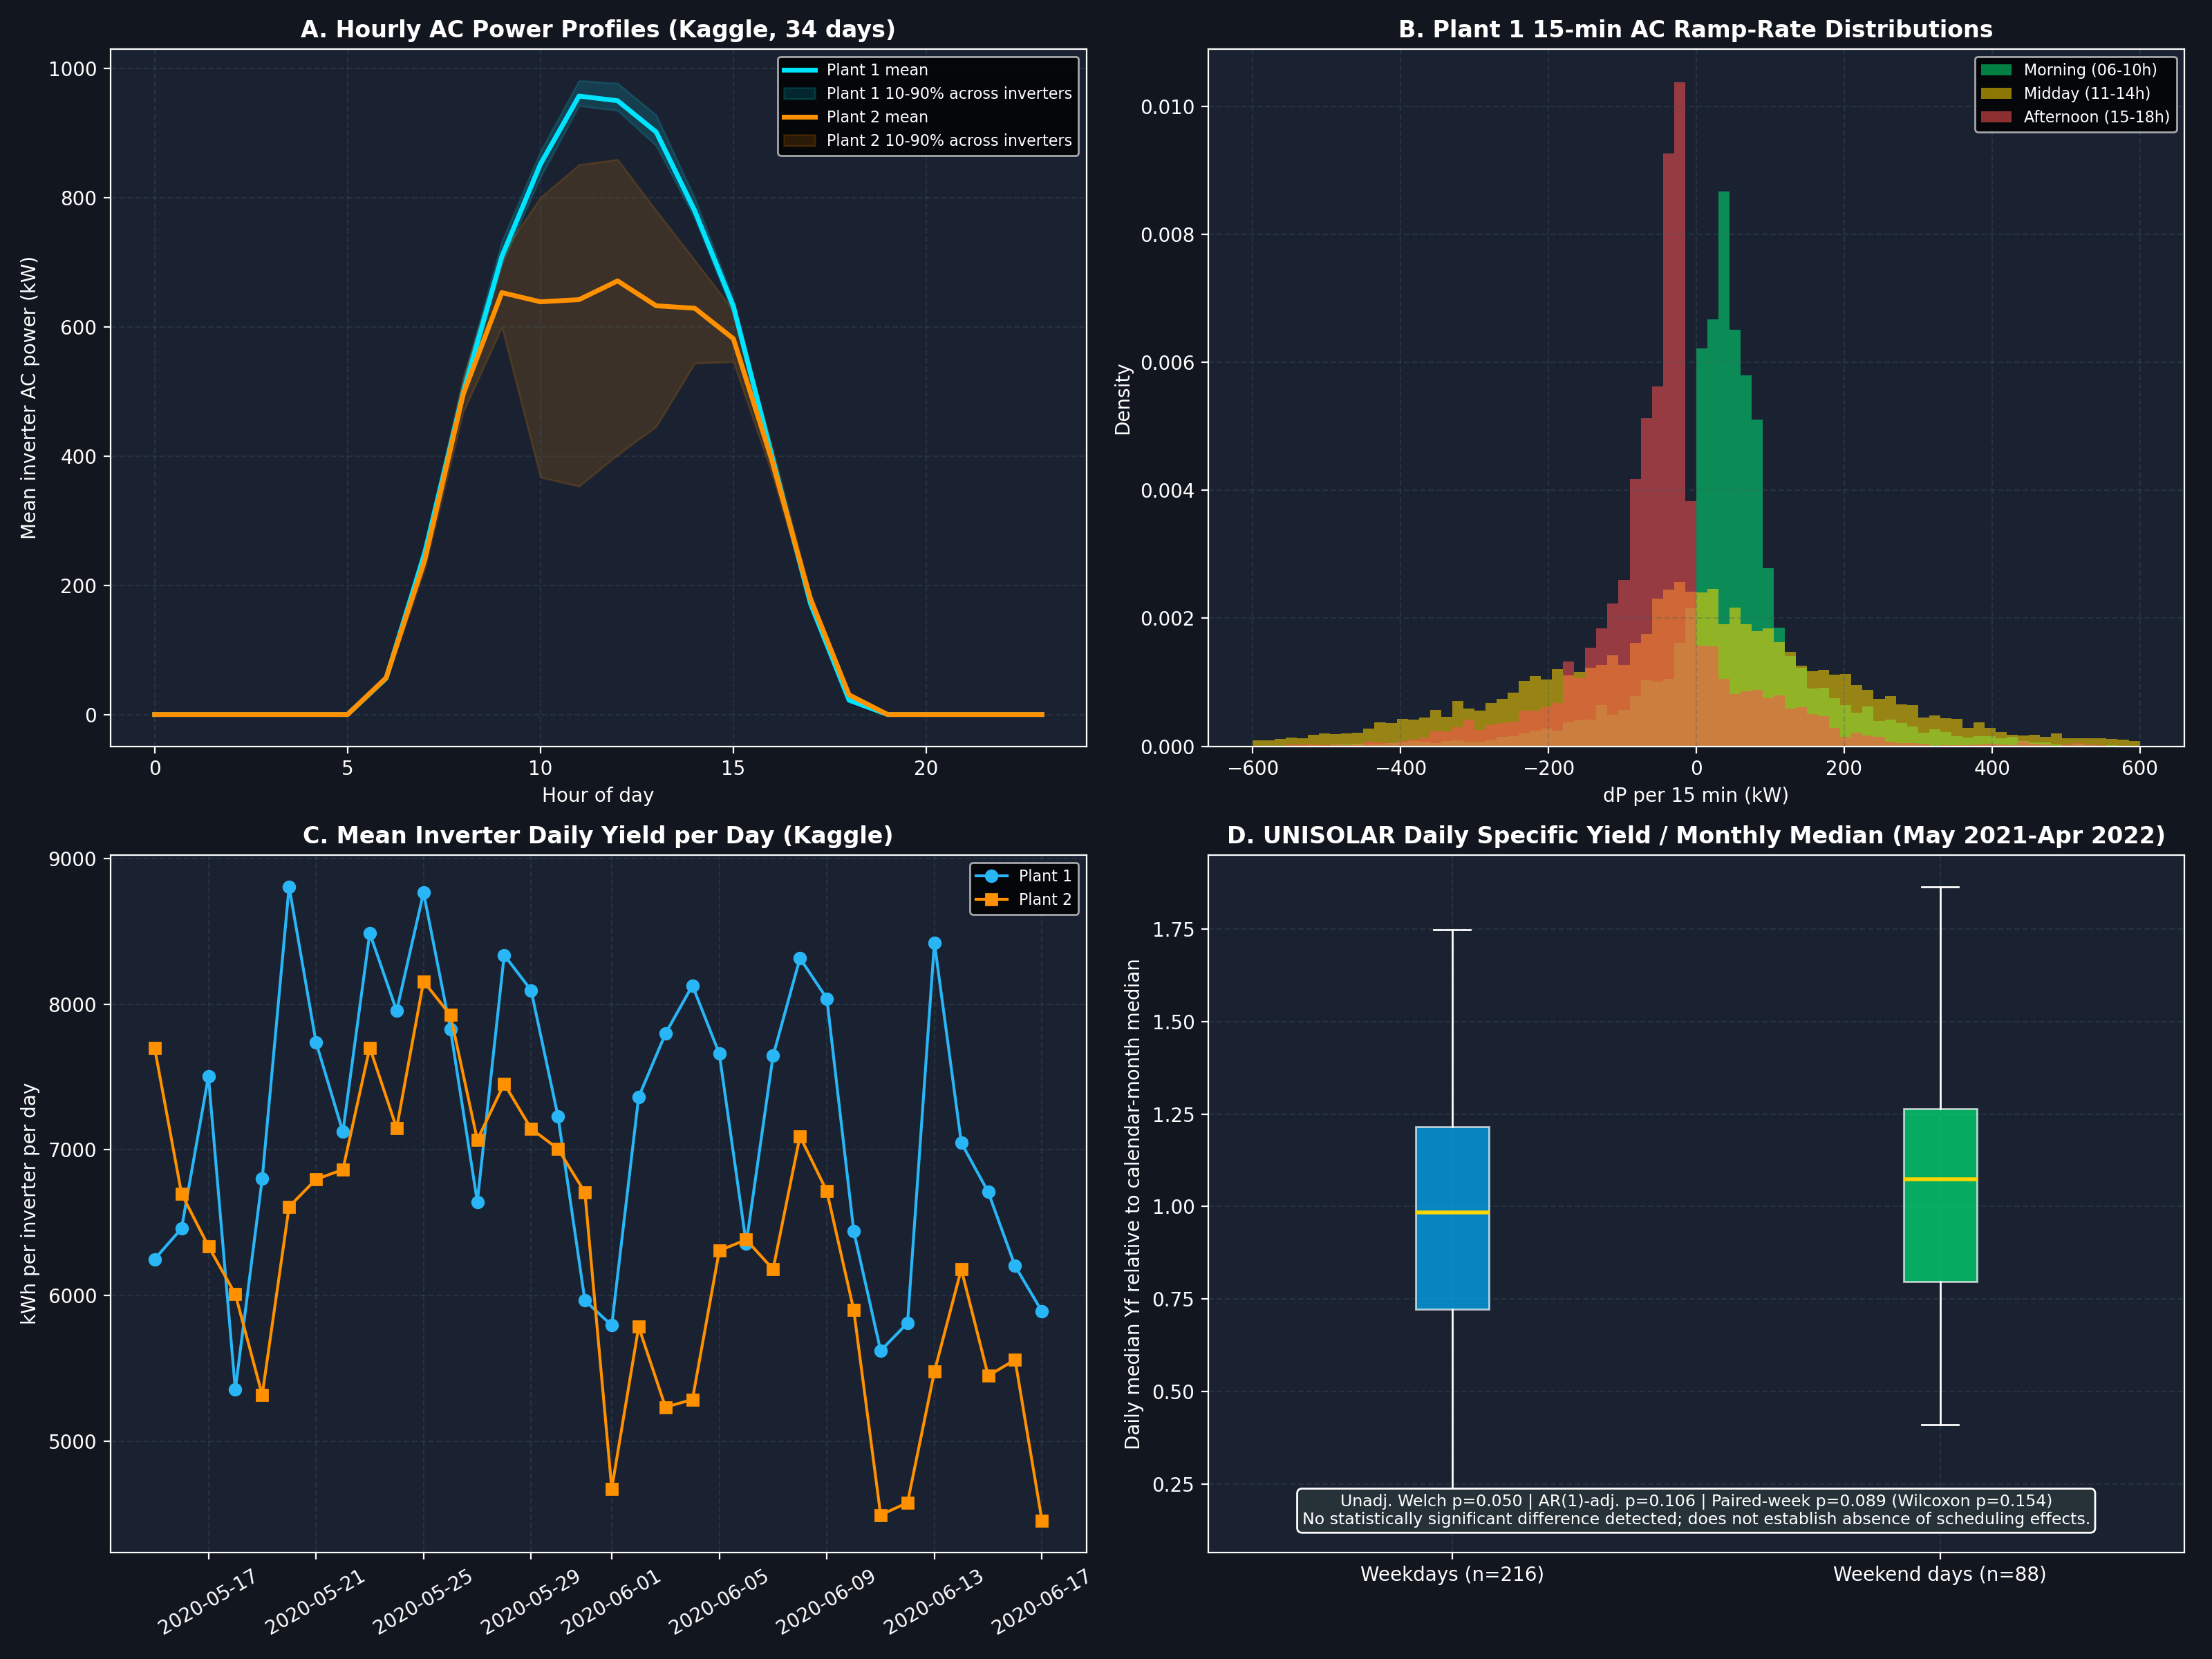

In [7]:
# ---------------------------------------------------------------
# Figure: temporal_intraday_and_weekday_invariance.png (regenerated with daily-unit comparison)
# ---------------------------------------------------------------
plt.style.use("dark_background")
fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor="#12161f")
for ax in axes.flat:
    ax.set_facecolor("#1a2130"); ax.grid(True, linestyle="--", alpha=0.3, color="#455a64")

# A. Hourly profiles (per-inverter mean AC power by hour)
ax = axes[0, 0]
for df, col, lab in ((p1_gen, "#00e5ff", "Plant 1"), (p2_gen, "#ff9100", "Plant 2")):
    h = df.groupby(["Hour", "SOURCE_KEY"])["AC_POWER"].mean().groupby("Hour")
    ax.plot(h.mean().index, h.mean().values, color=col, lw=2.5, label=f"{lab} mean")
    ax.fill_between(h.mean().index, h.quantile(0.1).values, h.quantile(0.9).values, color=col, alpha=0.15,
                    label=f"{lab} 10-90% across inverters")
ax.set_title("A. Hourly AC Power Profiles (Kaggle, 34 days)", fontsize=12, fontweight="bold")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean inverter AC power (kW)"); ax.legend(fontsize=8)

# B. Ramp-rate distributions
ax = axes[0, 1]
for (name, (h0, h1)), col in zip(windows.items(), ["#00e676", "#ffd600", "#ff5252"]):
    r = p1_active_ramps[p1_active_ramps["Hour"].between(h0, h1)]["ramp"]
    ax.hist(r, bins=80, range=(-600, 600), alpha=0.55, color=col, density=True, label=name)
ax.set_title("B. Plant 1 15-min AC Ramp-Rate Distributions", fontsize=12, fontweight="bold")
ax.set_xlabel("dP per 15 min (kW)"); ax.set_ylabel("Density"); ax.legend(fontsize=8)

# C. Inter-day variability
ax = axes[1, 0]
ax.plot(p1_daily.index, p1_daily.values, marker="o", color="#29b6f6", label="Plant 1")
ax.plot(p2_daily.index, p2_daily.values, marker="s", color="#ff9100", label="Plant 2")
ax.set_title("C. Mean Inverter Daily Yield per Day (Kaggle)", fontsize=12, fontweight="bold")
ax.set_ylabel("kWh per inverter per day"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)

# D. Daily-unit weekday vs weekend (UNISOLAR, seasonally adjusted)
ax = axes[1, 1]
data = [daily_fleet.loc[~daily_fleet["IsWeekend"], "yf_rel"], daily_fleet.loc[daily_fleet["IsWeekend"], "yf_rel"]]
bp = ax.boxplot(data, patch_artist=True, tick_labels=[f"Weekdays (n={len(data[0])})", f"Weekend days (n={len(data[1])})"],
                medianprops=dict(color="#ffd600", lw=2))
for patch, c in zip(bp["boxes"], ["#00b0ff", "#00e676"]):
    patch.set_facecolor(c); patch.set_alpha(0.7)
row = daily_test.iloc[-1]
ax.set_title("D. UNISOLAR Daily Specific Yield / Monthly Median (May 2021-Apr 2022)", fontsize=12, fontweight="bold")
ax.set_ylabel("Daily median Yf relative to calendar-month median")
ax.text(0.5, 0.04, f"Unadj. Welch p={row['Welch p']:.3f} | AR(1)-adj. p={p_e:.3f} | Paired-week p={tt.pvalue:.3f} (Wilcoxon p={wx.pvalue:.3f})\n"
        "No statistically significant difference detected; does not establish absence of scheduling effects.",
        transform=ax.transAxes, ha="center", fontsize=8.5, bbox=dict(boxstyle="round", facecolor="#263238"))
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "temporal_intraday_and_weekday_invariance.png"), dpi=200)
plt.close(fig)
Image(filename=os.path.join(FIG_DIR, "temporal_intraday_and_weekday_invariance.png"))

### Investigation 1 Findings & Qualified Statistical Interpretation

1. **15-Minute AC Power Ramp Rates — Kaggle Plant 1 (Calculated Result):**
   - **Morning (06:00–10:59, $n = 14,518$ active inverter-intervals):** Mean ramp is **$+47.91\text{ kW}$ per 15 min** ($\text{SD} = 113.66\text{ kW}$, 5th–95th percentile $[-136.02, +241.99]\text{ kW}$). *(Note: An earlier report text cited $+46.1\text{ kW}$ due to a transcription mismatch; $+47.91\text{ kW}$ is the exact executed result.)*
   - **Midday (11:00–14:59, $n = 11,694$):** Mean ramp is **$-11.80\text{ kW}$ per 15 min** with the highest dispersion (**$\text{SD} = 225.98\text{ kW}$**, 5th–95th percentile $[-397.49, +352.92]\text{ kW}$), reflecting rapid cloud-edge transients during peak irradiance hours.
   - **Afternoon (15:00–18:59, $n = 10,615$):** Mean ramp is **$-50.83\text{ kW}$ per 15 min** ($\text{SD} = 117.40\text{ kW}$, 5th–95th percentile $[-239.20, +132.32]\text{ kW}$).

2. **Inter-Day Yield Variability — Kaggle 34-Day Window (Calculated Result):**
   - Across the $34$ observed days, mean inverter daily yield ranges from **$5,351.7$ to $8,807.7\text{ kWh/day}$ ($1.65\times$)** at Plant 1 and **$4,453.0$ to $8,156.4\text{ kWh/day}$ ($1.83\times$)** at Plant 2.

3. **Weekday vs. Weekend Comparison — Methodology, Independence Check & Calibrated Conclusion:**
   - **Why the 15-minute interval-level Welch test has limited inferential validity:**
     - At the 15-minute interval level, UNISOLAR Campus 1 shows a weekday mean of **$6.8657\text{ kWh}$** ($n = 545,076$) vs. a weekend mean of **$6.8814\text{ kWh}$** ($n = 214,120$), a $+0.23\%$ difference with naive Welch $p = 0.5937$ *(earlier prose cited $p = 0.778$, which did not match the executed cell output of $0.5937$)*. Meanwhile, the same naive interval-level test yields $p = 0.0008$ on Plant 1 ($+2.53\%$) and $p < 0.0001$ on Plant 2 ($+7.65\%$).
     - However, 15-minute observations within the same day and across $22–27$ co-located inverters/sites are **heavily autocorrelated and spatially co-dependent** (a single sunny weekend day contributes $\sim 1,000$ pseudo-replicates). Treating $N > 10^4$ intervals as independent observations violates the i.i.d. assumption of the two-sample $t$-test and severely distorts $p$-values in both directions.
   - **Daily-unit and paired within-week comparisons (defensible units of analysis):**
     - **Kaggle Plant 1 ($n = 24$ weekdays vs. $10$ weekend days):** Mean daily inverter yield is $7,146.2$ vs. $7,307.2\text{ kWh/day}$ ($+2.25\%$, Welch $p = 0.6490$, Mann–Whitney $p = 0.7195$).
     - **Kaggle Plant 2 ($n = 24$ weekdays vs. $10$ weekend days):** Mean daily inverter yield is $6,189.6$ vs. $6,581.5\text{ kWh/day}$ ($+6.33\%$, Welch $p = 0.2036$, Mann–Whitney $p = 0.3544$). With only $10$ weekend days and daily lag-1 autocorrelation $r_1 = 0.314$ (P1) and $0.680$ (P2), statistical power over a 34-day window is low.
     - **UNISOLAR Campus 1 documented-$\text{kW}_p$ sites (`2021-05` to `2022-04`, $n = 216$ weekdays vs. $88$ weekend days with $\ge 10$ reporting sites):**
       - Unadjusted daily fleet median specific yield: weekday mean **$2.938\text{ kWh}/\text{kW}_p/\text{day}$** vs. weekend mean **$3.236\text{ kWh}/\text{kW}_p/\text{day}$** ($+10.13\%$, Welch $p = 0.1074$, Mann–Whitney $p = 0.0844$).
       - Seasonally adjusted daily series (daily median $Y_f$ divided by its calendar-month median): weekday mean $0.9746$ vs. weekend mean $1.0585$ ($+8.61\%$). A naive daily Welch test gives $p = 0.0498$ (Mann–Whitney $p = 0.0477$), **but consecutive days still exhibit positive synoptic weather persistence (lag-1 autocorrelation $r_1 = 0.193$)**.
       - Accounting for day-to-day dependence via (a) an AR(1) effective-sample-size adjustment ($n_{\text{eff}} = 146$ weekdays, $60$ weekend days) yields **$t = 1.626, p = 0.1055$**, and (b) a **paired within-week comparison across all $48$ complete calendar weeks** (weekend mean minus weekday mean within each week, eliminating seasonal drift and multi-week autocorrelation) yields a mean difference of $+0.0820$ with **one-sample $t$-test $p = 0.0895$** and **Wilcoxon signed-rank $p = 0.1537$** ($29/48$ weeks have higher weekend average).
   - **Calibrated Conclusion (Supported Interpretation):**
     > **No statistically significant weekday–weekend difference was detected in the analysed sample. This does not establish the absence of operational or scheduling effects.** In particular, campus-level export limits, inverter curtailment, or maintenance schedules could still occur on specific sites or days without producing a statistically detectable shift in fleet-wide daily aggregates.


---
## 4. Investigation 2 — Monthly & Seasonal Patterns Controlling for Fleet Composition

### Why Fleet-Wide Totals Cannot Independently Establish Seasonality
In UNISOLAR, the number of sites with rows in a given month grows from **$11$ sites in January–February 2020** to **$42$ sites from February 2021 onward**, while the monthly share of non-null rows ranges between **$30.79\%$ (July 2020)** and **$53.48\%$ (January 2020)**. Consequently, fleet-wide monthly energy sums confound seasonal solar variation with progressive site onboarding and varying telemetry completeness.

Below we:
1. Document the uncontrolled 28-month fleet summary for context.
2. Verify the geographic coordinates of all cinco campuses in `Solar_Site_Details.csv` before using Southern-Hemisphere seasonal labels.
3. Construct a **fixed, consistent site cohort** with explicit, a-priori completeness criteria and evaluate **four distinct generation metrics** alongside a threshold sensitivity matrix.


In [8]:
# ---------------------------------------------------------------
# Fleet-level monthly summary (changing fleet composition -- NOT a seasonal estimate on its own)
# ---------------------------------------------------------------
monthly_audit = uni_gen.groupby("YearMonth").agg(
    total_records=("SolarGeneration", "size"),
    valid_records=("SolarGeneration", lambda x: x.notna().sum()),
    reporting_sites=("SiteKey", "nunique"),
    mean_per_valid_obs=("SolarGeneration", "mean"),
    total_fleet_mwh=("SolarGeneration", lambda x: x.sum() / 1000.0),
).reset_index()
monthly_audit["completeness_pct"] = monthly_audit["valid_records"] / monthly_audit["total_records"] * 100
vd = site_day[site_day["valid_day"]].groupby("YearMonth").agg(valid_site_days=("SiteKey", "size"))
monthly_audit = monthly_audit.merge(vd, left_on="YearMonth", right_index=True, how="left")
print("=== UNISOLAR MONTHLY FLEET SUMMARY (all sites, changing composition) ===")
display(monthly_audit.round(2))

def assign_season(month):
    # Calendar seasons using the Southern-Hemisphere convention (justified by the coordinate check below)
    if month in (12, 1, 2): return "Summer (Dec-Feb)"
    if month in (3, 4, 5): return "Autumn (Mar-May)"
    if month in (6, 7, 8): return "Winter (Jun-Aug)"
    return "Spring (Sep-Nov)"
SEASON_ORDER = ["Summer (Dec-Feb)", "Autumn (Mar-May)", "Winter (Jun-Aug)", "Spring (Sep-Nov)"]

uni_gen["Season"] = uni_gen["Month"].map(assign_season)
fleet_season = uni_gen.groupby("Season")["SolarGeneration"].agg(valid_obs="count", mean_per_valid_obs="mean").loc[SEASON_ORDER]
print("\n=== FLEET-LEVEL MEAN PER VALID OBSERVATION BY SEASON (all 28 months, changing fleet) ===")
display(fleet_season.round(3))
fleet_ratio = fleet_season.loc["Summer (Dec-Feb)", "mean_per_valid_obs"] / fleet_season.loc["Winter (Jun-Aug)", "mean_per_valid_obs"]
print(f"Fleet-level summer/winter ratio of mean per valid observation: {fleet_ratio:.2f}x")

=== UNISOLAR MONTHLY FLEET SUMMARY (all sites, changing composition) ===


,YearMonth,total_records,valid_records,reporting_sites,mean_per_valid_obs,total_fleet_mwh,completeness_pct,valid_site_days
0,2020-01,30709,16422,11,9.12,149.82,53.48,257
1,2020-02,30624,15826,11,9.13,144.54,51.68,256
2,2020-03,35518,16667,13,8.79,146.43,46.93,309
3,2020-04,37440,16001,13,6.34,101.46,42.74,377
4,2020-05,38688,15268,13,5.31,81.11,39.46,393
5,2020-06,67855,22514,30,3.76,84.59,33.18,602
6,2020-07,86539,26644,33,4.81,128.26,30.79,485
7,2020-08,104541,37395,36,5.90,220.81,35.77,688
8,2020-09,100425,40206,36,6.88,276.45,40.04,728
9,2020-10,103192,47093,36,6.65,313.34,45.64,663



=== FLEET-LEVEL MEAN PER VALID OBSERVATION BY SEASON (all 28 months, changing fleet) ===


,valid_obs,mean_per_valid_obs
Season,,
Summer (Dec-Feb),377776,8.041
Autumn (Mar-May),290546,6.553
Winter (Jun-Aug),219325,4.895
Spring (Sep-Nov),307998,7.428


Fleet-level summer/winter ratio of mean per valid observation: 1.64x


In [9]:
# ---------------------------------------------------------------
# Coordinate verification before using hemisphere-specific season labels
# ---------------------------------------------------------------
coords = uni_meta.groupby("CampusKey").agg(sites=("SiteKey", "count"), lat=("lat", "first"), lon=("Lon", "first"),
                                           lat_unique=("lat", "nunique"), documented_kWp_sites=("kWp", "count"))
display(coords)
print(f"All site latitudes negative (Southern Hemisphere): {(uni_meta['lat'] < 0).all()}")
print(f"Latitude range: {uni_meta['lat'].min():.3f} to {uni_meta['lat'].max():.3f} | "
      f"Longitude range: {uni_meta['Lon'].min():.3f} to {uni_meta['Lon'].max():.3f}")

,sites,lat,lon,lat_unique,documented_kWp_sites
CampusKey,,,,,
1,27,-37.718287,145.050975,1,25
2,5,-36.111209,146.848679,1,0
3,8,-36.778858,144.301232,1,0
4,1,-34.205289,142.166556,1,0
5,1,-36.380319,145.406290,1,0


All site latitudes negative (Southern Hemisphere): True
Latitude range: -37.718 to -34.205 | Longitude range: 142.167 to 146.849


### Geographic Coordinate Verification (Verified Observation)

- All $42$ sites in `Solar_Site_Details.csv` have negative (Southern Hemisphere) latitudes between **$-37.718^\circ\text{ S}$ and $-34.205^\circ\text{ S}$** and longitudes between **$142.167^\circ\text{ E}$ and $146.849^\circ\text{ E}$** (all 5 La Trobe University campuses in Victoria, southeastern Australia: Campus 1 Bundoora/Melbourne $-37.718^\circ\text{ S}$, Campus 2 Albury-Wodonga $-36.111^\circ\text{ S}$, Campus 3 Bendigo $-36.779^\circ\text{ S}$, Campus 4 Mildura $-34.205^\circ\text{ S}$, Campus 5 Shepparton $-36.380^\circ\text{ S}$).
- Because the coordinates directly confirm a mid-latitude Southern Hemisphere location, grouping calendar months into **Summer (Dec–Feb), Autumn (Mar–May), Winter (Jun–Aug), and Spring (Sep–Nov)** is geographically supported.
- **Temporal scope boundary:** The dataset covers **28 months (`2020-01` to `2022-04`)**, i.e., slightly more than two annual cycles. All seasonal figures reported below describe **empirical patterns within the observed 28-month period** and must **not** be interpreted as long-term climatological normals. The 34-day Kaggle datasets (`2020-05-15` to `2020-06-17`) are excluded from seasonal analysis altogether.


In [10]:
# ---------------------------------------------------------------
# Consistent site cohort for seasonal comparison
# ---------------------------------------------------------------
MIN_VALID_DAYS_PER_MONTH = 10      # a-priori: roughly one third of a month of valid days
window_months = pd.period_range(WINDOW_START, WINDOW_END, freq="M")

def build_cohort(sd, months, min_days):
    counts = (sd[sd["valid_day"] & sd["YearMonth"].isin(months)]
              .groupby(["SiteKey", "YearMonth"]).size().unstack(fill_value=0)
              .reindex(columns=months, fill_value=0))
    ok = (counts >= min_days).all(axis=1)
    return sorted(ok[ok].index.tolist()), counts

cohort_sites, cohort_counts = build_cohort(site_day, window_months, MIN_VALID_DAYS_PER_MONTH)
all_sites = sorted(uni_meta["SiteKey"].tolist())
excluded = [s for s in all_sites if s not in cohort_sites]
cohort_kwp = [s for s in cohort_sites if pd.notna(uni_meta.set_index("SiteKey").loc[s, "kWp"])]

print(f"Window: {WINDOW_START} to {WINDOW_END} ({len(window_months)} months)")
print(f"Inclusion: valid site-day (96 rows, >= {CORE_MIN_VALID}/{CORE_N} core intervals) on >= {MIN_VALID_DAYS_PER_MONTH} days in EVERY month")
print(f"Cohort sites ({len(cohort_sites)}): {cohort_sites}")
print(f"Cohort sites with documented kWp ({len(cohort_kwp)}): {cohort_kwp}")
print("\nExcluded sites and their minimum monthly valid-day count within the window:")
excl = cohort_counts.reindex(excluded).fillna(0)
display(pd.DataFrame({"min_valid_days_in_any_month": excl.min(axis=1).astype(int),
                      "months_below_threshold": (excl < MIN_VALID_DAYS_PER_MONTH).sum(axis=1)}))

Window: 2021-05 to 2022-04 (12 months)
Inclusion: valid site-day (96 rows, >= 26/28 core intervals) on >= 10 days in EVERY month
Cohort sites (37): [1, 2, 3, 4, 6, 8, 9, 10, 11, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 42]
Cohort sites with documented kWp (24): [15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]

Excluded sites and their minimum monthly valid-day count within the window:


,min_valid_days_in_any_month,months_below_threshold
SiteKey,,
5,4,1
7,0,7
12,8,2
14,4,1
41,8,2


In [11]:
# ---------------------------------------------------------------
# Monthly profiles for the fixed cohort -- four distinct metrics
# ---------------------------------------------------------------
coh = site_day[site_day["SiteKey"].isin(cohort_sites) & site_day["valid_day"] & site_day["YearMonth"].isin(window_months)]

# Site-month mean daily energy (kWh/day) and specific yield (kWh/kWp/day)
site_month = coh.groupby(["SiteKey", "YearMonth"]).agg(mean_daily_kwh=("energy_kwh", "mean"),
                                                       mean_yf=("specific_yield", "mean"),
                                                       valid_days=("energy_kwh", "size")).reset_index()
site_month["Season"] = site_month["YearMonth"].dt.month.map(assign_season)

win_fleet = monthly_audit[monthly_audit["YearMonth"].isin(window_months)].set_index("YearMonth")
cohort_monthly = pd.DataFrame({
    "fleet_total_mwh (all sites)": win_fleet["total_fleet_mwh"],
    "fleet_mean_per_valid_obs_kwh": win_fleet["mean_per_valid_obs"],
    "cohort_sum_of_site_mean_daily_kwh": site_month.groupby("YearMonth")["mean_daily_kwh"].sum(),
    "cohort_median_site_daily_kwh": site_month.groupby("YearMonth")["mean_daily_kwh"].median(),
    "cohort_kwp_median_yf": site_month[site_month["SiteKey"].isin(cohort_kwp)].groupby("YearMonth")["mean_yf"].median(),
})
print("=== MONTHLY PROFILES: FLEET vs FIXED COHORT ===")
display(cohort_monthly.round(3))

# Seasonal aggregation of each metric (mean of monthly values within season)
cm = cohort_monthly.copy()
cm["Season"] = cm.index.month.map(assign_season)
season_tbl = cm.groupby("Season").mean().loc[SEASON_ORDER]
display(season_tbl.round(3))
ratios = season_tbl.loc["Summer (Dec-Feb)"] / season_tbl.loc["Winter (Jun-Aug)"]
print("Summer / winter ratio by metric (window May 2021-Apr 2022):")
display(ratios.round(2).to_frame("summer_to_winter_ratio"))

# Within-site seasonal ratio (needs no kWp -- each site is its own reference)
site_season = site_month.groupby(["SiteKey", "Season"])["mean_daily_kwh"].mean().unstack()
site_season["summer_winter_ratio"] = site_season["Summer (Dec-Feb)"] / site_season["Winter (Jun-Aug)"]
r = site_season["summer_winter_ratio"]
print(f"Within-site summer/winter daily-energy ratio across {r.notna().sum()} cohort sites: "
      f"median={r.median():.2f}, IQR=[{r.quantile(0.25):.2f}, {r.quantile(0.75):.2f}], min={r.min():.2f}, max={r.max():.2f}")

=== MONTHLY PROFILES: FLEET vs FIXED COHORT ===


,fleet_total_mwh (all sites),fleet_mean_per_valid_obs_kwh,cohort_sum_of_site_mean_daily_kwh,cohort_median_site_daily_kwh,cohort_kwp_median_yf
YearMonth,,,,,
2021-05,222.701,4.972,7262.296,105.781,1.822
2021-06,169.529,3.986,5396.149,82.806,1.440
2021-07,179.183,4.240,5595.522,89.155,1.568
2021-08,291.280,6.071,9165.773,137.982,2.377
2021-09,416.448,7.609,12853.955,200.710,3.430
2021-10,479.439,8.035,13984.622,221.052,3.762
2021-11,432.483,7.580,13457.034,215.054,3.661
2021-12,546.116,8.477,15506.597,275.660,4.007
2022-01,538.324,8.418,16182.057,256.595,4.454


,fleet_total_mwh (all sites),fleet_mean_per_valid_obs_kwh,cohort_sum_of_site_mean_daily_kwh,cohort_median_site_daily_kwh,cohort_kwp_median_yf
Season,,,,,
Summer (Dec-Feb),515.483,8.437,15850.705,263.128,4.328
Autumn (Mar-May),294.696,6.115,9767.807,148.938,2.607
Winter (Jun-Aug),213.331,4.766,6719.148,103.314,1.795
Spring (Sep-Nov),442.790,7.741,13431.870,212.272,3.618


Summer / winter ratio by metric (window May 2021-Apr 2022):


,summer_to_winter_ratio
fleet_total_mwh (all sites),2.42
fleet_mean_per_valid_obs_kwh,1.77
cohort_sum_of_site_mean_daily_kwh,2.36
cohort_median_site_daily_kwh,2.55
cohort_kwp_median_yf,2.41


Within-site summer/winter daily-energy ratio across 37 cohort sites: median=2.46, IQR=[2.30, 2.58], min=1.63, max=2.93


In [12]:
# ---------------------------------------------------------------
# Sensitivity of the cohort seasonal ratio to the inclusion thresholds
# ---------------------------------------------------------------
def cohort_ratio(core_frac, min_days, months, exclude=()):
    sd = site_day.copy()
    sd["valid_day"] = flag_valid_days(sd, math.ceil(core_frac * CORE_N))
    sites, _ = build_cohort(sd, months, min_days)
    sites = [s for s in sites if s not in exclude]
    c = sd[sd["SiteKey"].isin(sites) & sd["valid_day"] & sd["YearMonth"].isin(months)]
    sm = c.groupby(["SiteKey", "YearMonth"]).agg(d=("energy_kwh", "mean"), yf=("specific_yield", "mean")).reset_index()
    sm["Season"] = sm["YearMonth"].dt.month.map(assign_season)
    ss = sm.groupby(["SiteKey", "Season"])["d"].mean().unstack()
    within = (ss.get("Summer (Dec-Feb)") / ss.get("Winter (Jun-Aug)")).median() if {"Summer (Dec-Feb)", "Winter (Jun-Aug)"} <= set(ss.columns) else np.nan
    kw = sm.dropna(subset=["yf"]).groupby("YearMonth")["yf"].median()
    kws = kw.groupby(kw.index.month.map(assign_season)).mean()
    kwr = kws.get("Summer (Dec-Feb)", np.nan) / kws.get("Winter (Jun-Aug)", np.nan)
    return {"sites": len(sites), "kWp_sites": int(sm.dropna(subset=["yf"])["SiteKey"].nunique()),
            "median_within_site_ratio": within, "median_Yf_ratio": kwr}

sens = []
for frac in (1.00, 0.90, 0.75, 0.50):
    for md in (10, 15):
        sens.append({"core_threshold": frac, "min_valid_days": md, **cohort_ratio(frac, md, window_months)})
sens.append({"core_threshold": 0.90, "min_valid_days": 10, "note": "excl. Sites 19 & 24",
             **cohort_ratio(0.90, 10, window_months, exclude=(19, 24))})
alt_months = pd.period_range("2020-09", "2021-08", freq="M")
sens.append({"core_threshold": 0.90, "min_valid_days": 10, "note": "alt window Sep 2020-Aug 2021",
             **cohort_ratio(0.90, 10, alt_months)})
sens_df = pd.DataFrame(sens)
print("=== SENSITIVITY OF SUMMER/WINTER RATIO TO INCLUSION CHOICES ===")
display(sens_df.round(2))

=== SENSITIVITY OF SUMMER/WINTER RATIO TO INCLUSION CHOICES ===


,core_threshold,min_valid_days,sites,kWp_sites,median_within_site_ratio,median_Yf_ratio,note
0,1.00,10,11,11,2.27,2.30,NaN
1,1.00,15,1,1,2.40,2.40,NaN
2,0.90,10,37,24,2.46,2.41,NaN
3,0.90,15,16,12,2.47,2.39,NaN
4,0.75,10,39,24,2.57,2.48,NaN
5,0.75,15,38,24,2.56,2.48,NaN
6,0.50,10,40,24,2.56,2.50,NaN
7,0.50,15,39,24,2.55,2.50,NaN
8,0.90,10,35,22,2.48,2.42,excl. Sites 19 & 24
9,0.90,10,28,21,2.16,2.12,alt window Sep 2020-Aug 2021


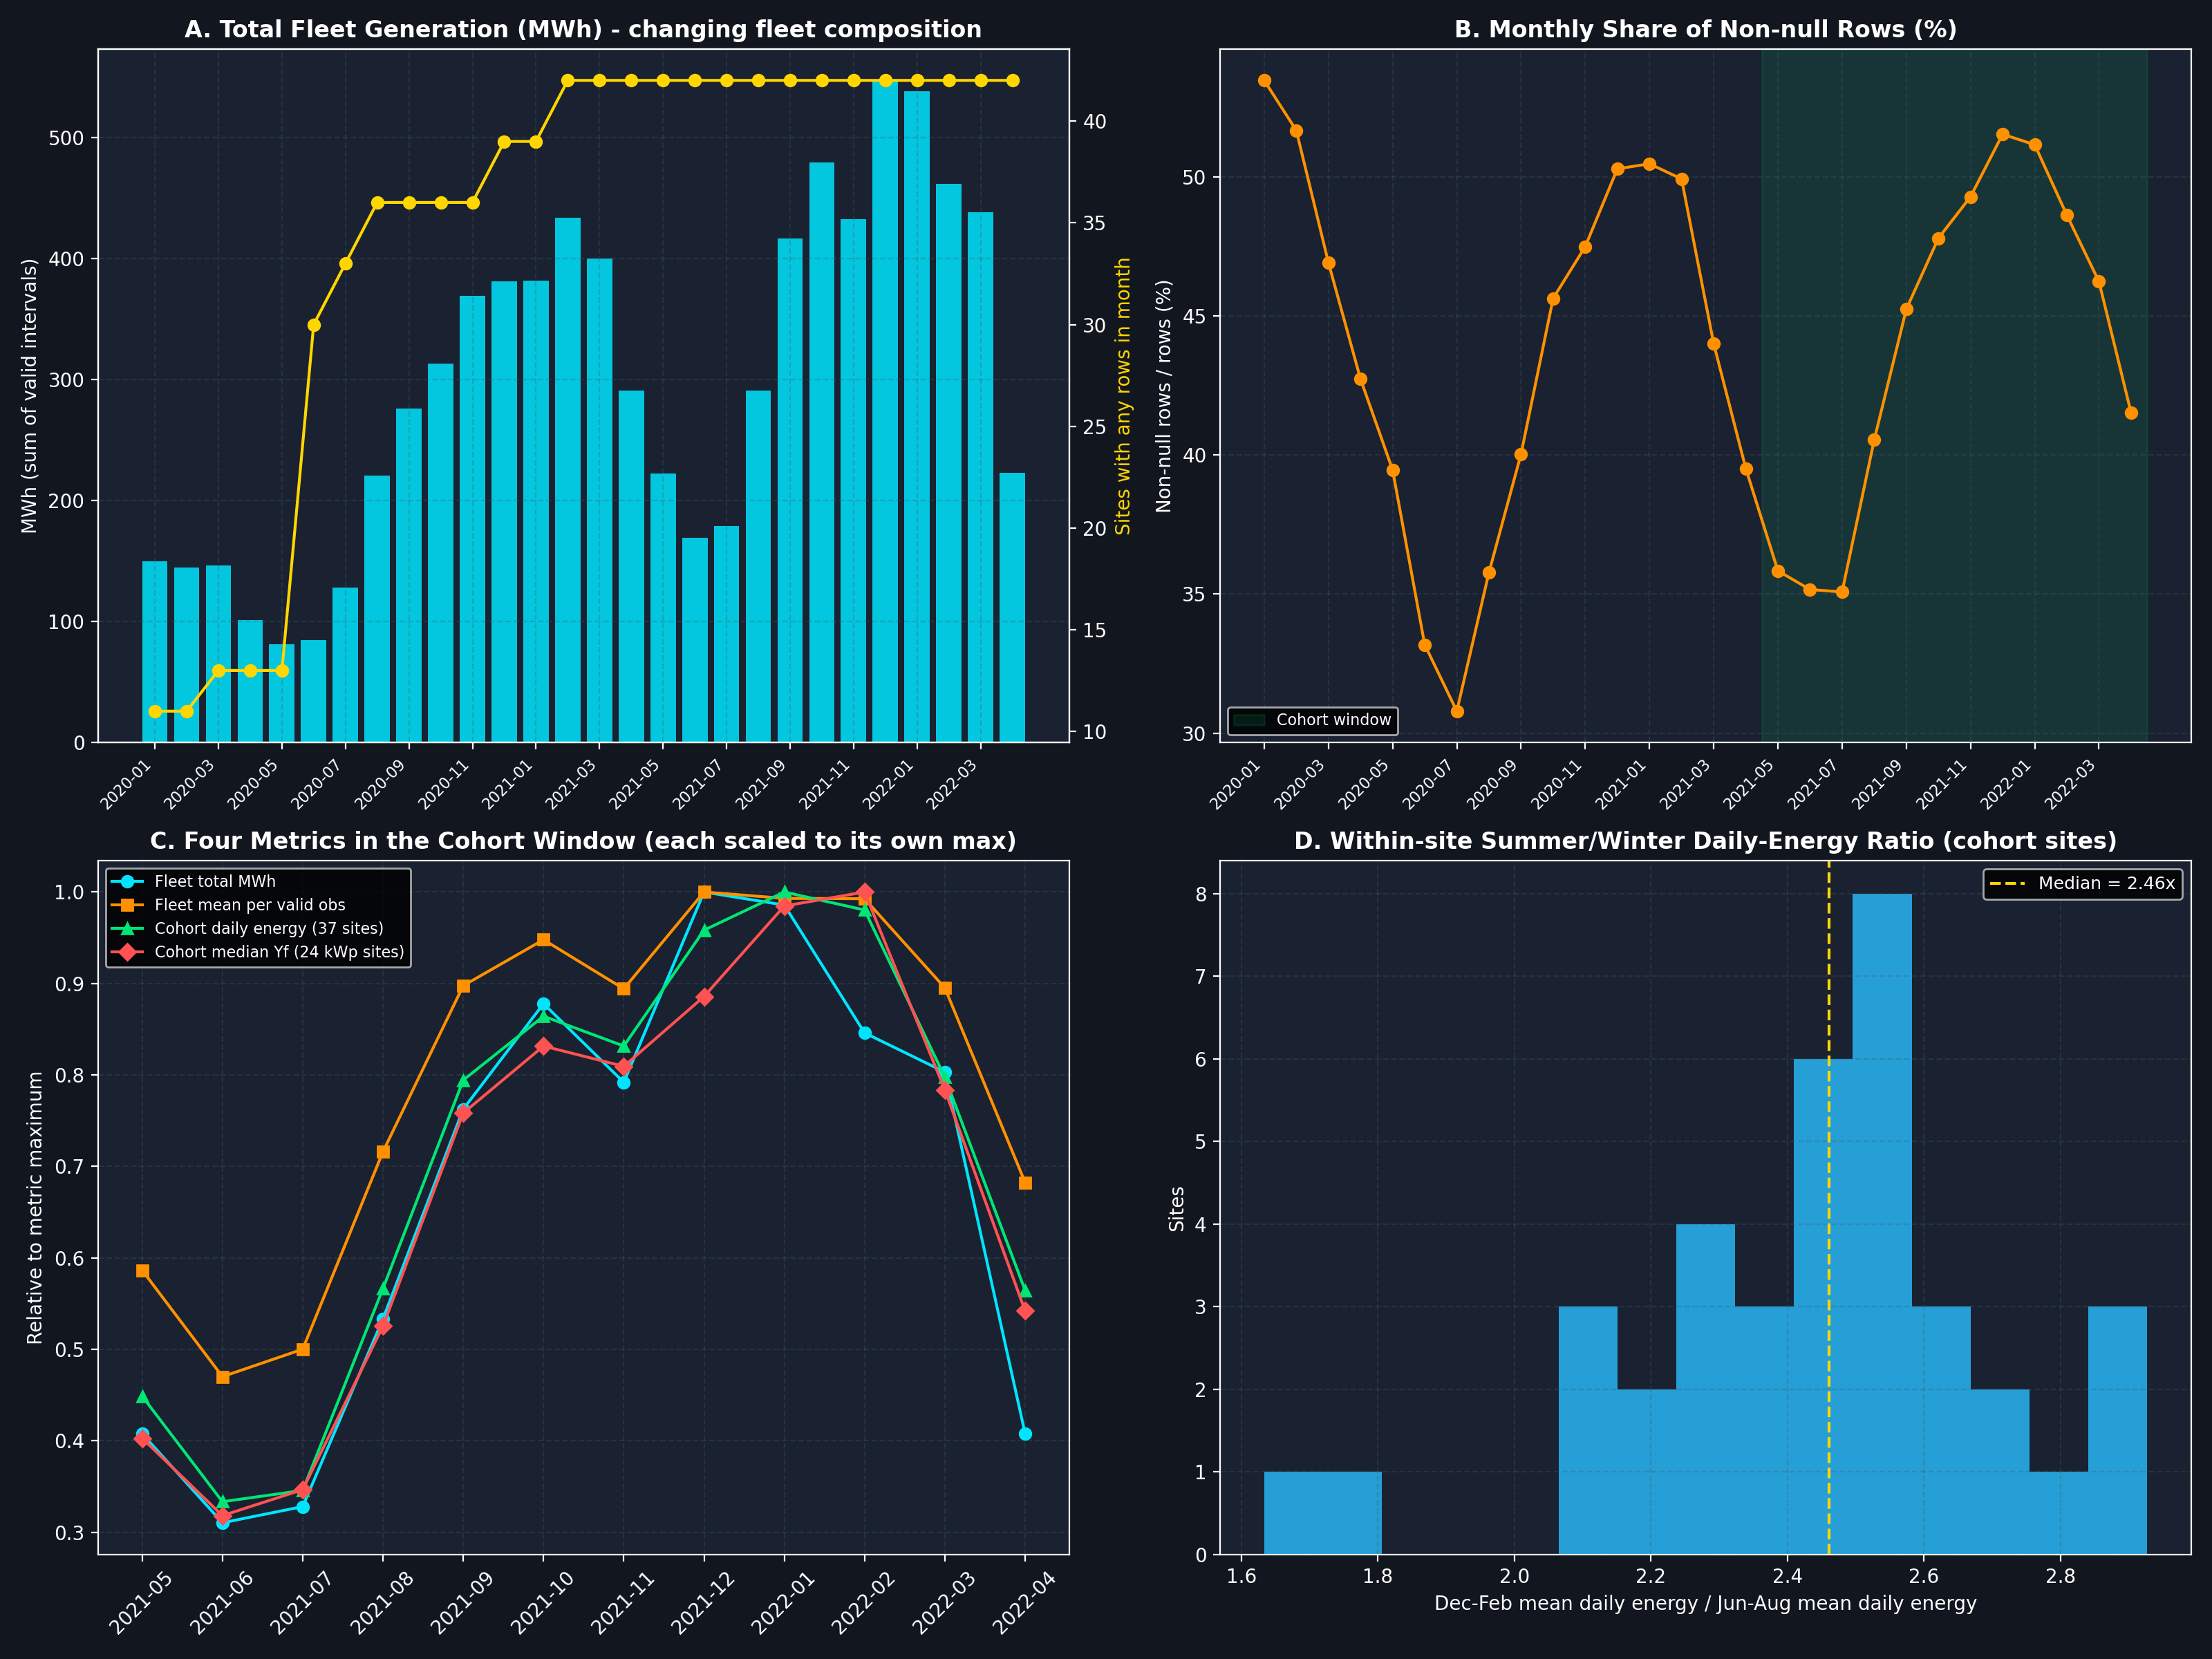

In [13]:
# ---------------------------------------------------------------
# Figure: unisolar_monthly_and_seasonal_trends.png (regenerated: fleet vs fixed cohort)
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor="#12161f")
for ax in axes.flat:
    ax.set_facecolor("#1a2130"); ax.grid(True, linestyle="--", alpha=0.3, color="#455a64")
x = monthly_audit["YearMonth"].astype(str)
ax = axes[0, 0]
ax.bar(range(len(x)), monthly_audit["total_fleet_mwh"], color="#00e5ff", alpha=0.85)
ax2 = ax.twinx(); ax2.plot(range(len(x)), monthly_audit["reporting_sites"], color="#ffd600", marker="o", lw=1.5)
ax2.set_ylabel("Sites with any rows in month", color="#ffd600")
ax.set_xticks(range(0, len(x), 2)); ax.set_xticklabels(x[::2], rotation=45, ha="right", fontsize=8)
ax.set_title("A. Total Fleet Generation (MWh) - changing fleet composition", fontsize=12, fontweight="bold")
ax.set_ylabel("MWh (sum of valid intervals)")

ax = axes[0, 1]
ax.plot(range(len(x)), monthly_audit["completeness_pct"], color="#ff9100", marker="o")
ax.set_xticks(range(0, len(x), 2)); ax.set_xticklabels(x[::2], rotation=45, ha="right", fontsize=8)
ax.axvspan(list(x).index(str(WINDOW_START)) - 0.5, list(x).index(str(WINDOW_END)) + 0.5, color="#00e676", alpha=0.1,
           label="Cohort window")
ax.set_title("B. Monthly Share of Non-null Rows (%)", fontsize=12, fontweight="bold")
ax.set_ylabel("Non-null rows / rows (%)"); ax.legend(fontsize=8)

ax = axes[1, 0]
xm = cohort_monthly.index.astype(str)
norm = lambda s: s / s.max()
ax.plot(xm, norm(cohort_monthly["fleet_total_mwh (all sites)"]), marker="o", color="#00e5ff", label="Fleet total MWh")
ax.plot(xm, norm(cohort_monthly["fleet_mean_per_valid_obs_kwh"]), marker="s", color="#ff9100", label="Fleet mean per valid obs")
ax.plot(xm, norm(cohort_monthly["cohort_sum_of_site_mean_daily_kwh"]), marker="^", color="#00e676",
        label=f"Cohort daily energy ({len(cohort_sites)} sites)")
ax.plot(xm, norm(cohort_monthly["cohort_kwp_median_yf"]), marker="D", color="#ff5252",
        label=f"Cohort median Yf ({len(cohort_kwp)} kWp sites)")
ax.set_title("C. Four Metrics in the Cohort Window (each scaled to its own max)", fontsize=12, fontweight="bold")
ax.tick_params(axis="x", rotation=45); ax.set_ylabel("Relative to metric maximum"); ax.legend(fontsize=8)

ax = axes[1, 1]
ax.hist(site_season["summer_winter_ratio"].dropna(), bins=15, color="#29b6f6", alpha=0.85)
ax.axvline(site_season["summer_winter_ratio"].median(), color="#ffd600", ls="--",
           label=f"Median = {site_season['summer_winter_ratio'].median():.2f}x")
ax.set_title("D. Within-site Summer/Winter Daily-Energy Ratio (cohort sites)", fontsize=12, fontweight="bold")
ax.set_xlabel("Dec-Feb mean daily energy / Jun-Aug mean daily energy"); ax.set_ylabel("Sites"); ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "unisolar_monthly_and_seasonal_trends.png"), dpi=200)
plt.close(fig)
Image(filename=os.path.join(FIG_DIR, "unisolar_monthly_and_seasonal_trends.png"))

### Investigation 2 Findings — Consistent Cohort vs. Changing Fleet

1. **Cohort Definition & Justification of Inclusion Criteria:**
   - **Comparison window:** **`2021-05` to `2022-04` (12 consecutive calendar months, 1 full annual cycle)**, chosen a priori as the latest complete 12-month cycle in the dataset—after all $42$ sites had entered the file by February 2021. (An earlier 12-month window `2020-09` to `2021-08` is also evaluated in the sensitivity table.)
   - **Site-day validity:** 96 rows present and $\ge 26/28$ ($90\%$) non-null intervals in the 09:00–15:45 core window.
   - **Monthly site inclusion threshold:** A site must have **$\ge 10$ valid site-days in every one of the 12 calendar months** ($pprox 1/3$ of a month, ensuring every site-month mean is estimated from at least 10 complete daily profiles).
   - **Resulting cohort:** **$37$ of $42$ sites qualify** (`SiteKey` 1–4, 6, 8–11, 13, 15–40, 42), of which **$24$ sites have documented $\text{kW}_p$** on Campus 1 (`SiteKey` 15–27, 30–40). Five sites are excluded because of specific low-coverage months: Site 7 ($0$ valid days in 7 months), Site 5 ($4$ valid days in 1 month), Site 14 ($4$ valid days in 1 month), Site 12 ($8$ valid days in 2 months), and Site 41 ($8$ valid days in 2 months).

2. **Four Clearly Distinguished Generation Metrics (May 2021 – April 2022 Window):**

| Metric | Definition | Summer (Dec–Feb) | Autumn (Mar–May) | Winter (Jun–Aug) | Spring (Sep–Nov) | Summer / Winter Ratio |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: |
| **1. Total fleet generation (MWh/month)** | Uncontrolled sum of all valid intervals across all reporting sites | $515.48$ | $294.70$ | $213.33$ | $442.79$ | **$2.42\times$** |
| **2. Average generation per valid observation (kWh / 15-min)** | Mean over non-null 15-min records only (ignores how many daylight hours were above the $0.1\text{ kWh}$ floor) | $8.437$ | $6.115$ | $4.766$ | $7.741$ | **$1.77\times$** *(28-mo fleet: $1.64\times$)* |
| **3. Cohort site-level daily energy (kWh/day)** | Fixed $37$-site cohort on valid site-days: sum of site mean daily energy / median site daily energy | $15,850.7$ (sum)<br>$263.13$ (median) | $9,767.8$<br>$148.94$ | $6,719.1$<br>$103.31$ | $13,431.9$<br>$212.27$ | **$2.36\times$ (sum)**<br>**$2.55\times$ (median)** |
| **4. Cohort capacity-normalised specific yield $Y_f$ ($\text{kWh}/\text{kW}_p/\text{day}$)** | Fixed $24$-site documented-$\text{kW}_p$ cohort on valid site-days, median across sites | **$4.328$** | **$2.607$** | **$1.795$** | **$3.618$** | **$2.41\times$** *($2.42\times$ excl. Sites 19 & 24)* |

3. **How Controlling for Fleet Composition & Metric Definition Changes the Seasonal Finding:**
   - **Why the earlier $1.70\times$ ($1.64\times$ exact 28-month fleet) ratio understated the true daily seasonal swing:**
     1. *Metric distortion from the $0.1\text{ kWh}$ recording floor:* Metric 2 (`mean_per_valid_obs`) averages only over non-null intervals. In winter, shorter day length means early-morning and late-afternoon hours are `NaN`, so the non-null average is taken over a shorter, more midday-concentrated window—artificially raising the winter per-interval mean relative to full-day energy.
     2. *Changing fleet composition in 2020:* Over the full 28 months, only $3$ sites (`SiteKey` 1, 3, 10 — none with documented $\text{kW}_p$) have $\ge 10$ valid days in all 28 months, because most Campus 1 sites first appear in June–December 2020.
   - **Controlled cohort result (Calculated Result):** When evaluated on the fixed 37-site cohort (`2021-05` to `2022-04`) using valid site-day energy sums, summer daily generation is **$2.36\times$ to $2.55\times$** winter daily generation:
     - Capacity-normalised median specific yield ($24$ documented-$\text{kW}_p$ cohort sites) rises from **$1.440\text{ kWh}/\text{kW}_p/\text{day}$ in June 2021** (winter minimum; winter season mean **$1.795$**) to **$4.524\text{ kWh}/\text{kW}_p/\text{day}$ in February 2022** (summer season mean **$4.328$**), a **$2.41\times$** seasonal ratio ($2.42\times$ when excluding anomalous Sites 19 and 24).
     - Across all $37$ cohort sites (requiring no $\text{kW}_p$ metadata because each site serves as its own baseline), the within-site summer-to-winter daily energy ratio has **median $2.46\times$** (IQR $[2.30\times, 2.58\times]$, range $[1.63\times, 2.93\times]$).
   - **Sensitivity across thresholds:** Varying the core-window threshold from $100\%$ ($28/28$) to $50\%$ ($14/28$) and minimum valid days from $10$ to $15$ keeps the median within-site ratio between **$2.27\times$ and $2.57\times$** and the median $Y_f$ ratio between **$2.30\times$ and $2.50\times$**. Using the earlier 12-month window `2020-09` to `2021-08` ($28$ sites, $21$ with $\text{kW}_p$) yields **$2.16\times$** within-site and **$2.12\times$** for $Y_f$.


---
## 5. Investigation 3 — Site-Wise Analysis, Corrected Specific Yield & Provisional Concerns

### Analytical Objectives:
1. Replace the distorted interval-mean formula ($\text{mean}_{\text{valid}} \times 96 / \text{kW}_p$) with **valid site-day energy sums divided by documented $\text{kW}_p$**, and report both full-record and cohort-window (`2021-05` to `2022-04`) specific yields for all 25 documented-$\text{kW}_p$ sites on Campus 1.
2. Correct the interpretation of first observed timestamps (Site 16, Site 39, and all other sites) so that dataset entry dates are never conflated with confirmed physical commissioning dates.
3. Preserve the numerical anomaly evidence for **Sites 19 and 24** while keeping their physical explanations strictly classified as **plausible hypotheses** and retaining Sites 16, 19, 24, and 39 as **provisional data-quality concerns** without automatic exclusion.


In [14]:
# ---------------------------------------------------------------
# Site-wise summary and CORRECTED capacity-normalised yield
# ---------------------------------------------------------------
site_summary = uni_gen.groupby("SiteKey").agg(
    CampusKey=("CampusKey", "first"),
    total_rows=("SolarGeneration", "size"),
    valid_rows=("SolarGeneration", "count"),
    mean_per_valid_obs=("SolarGeneration", "mean"),
    max_interval_kwh=("SolarGeneration", "max"),
    first_row=("DT", "min"),
    first_valid=("DT", lambda s: s[uni_gen.loc[s.index, "SolarGeneration"].notna()].min()),
    last_row=("DT", "max"),
).reset_index().merge(uni_meta[["SiteKey", "kWp"]], on="SiteKey", how="left")

vd_all = site_day[site_day["valid_day"]].groupby("SiteKey").agg(valid_days=("energy_kwh", "size"),
                                                               mean_daily_kwh=("energy_kwh", "mean"),
                                                               yf_full_record=("specific_yield", "mean"))
vd_win = (site_day[site_day["valid_day"] & site_day["YearMonth"].isin(window_months)]
          .groupby("SiteKey").agg(valid_days_window=("energy_kwh", "size"), yf_window=("specific_yield", "mean")))
site_summary = site_summary.merge(vd_all, on="SiteKey", how="left").merge(vd_win, on="SiteKey", how="left")
site_summary["cf_window_pct"] = site_summary["yf_window"] / 24 * 100
# Previous (incorrect) formula, shown only for transparency
site_summary["yf_previous_formula"] = site_summary["mean_per_valid_obs"] * 96 / site_summary["kWp"]
site_summary["peak_interval_vs_stc_pct"] = site_summary["max_interval_kwh"] / (site_summary["kWp"] * 0.25) * 100

kwp_tbl = site_summary[site_summary["kWp"].notna()].sort_values("yf_window", ascending=False)
cols = ["SiteKey", "kWp", "valid_days", "valid_days_window", "mean_daily_kwh", "yf_full_record", "yf_window",
        "cf_window_pct", "yf_previous_formula", "peak_interval_vs_stc_pct"]
print("=== DOCUMENTED-kWp SITES: CORRECTED SPECIFIC YIELD (kWh/kWp/day, valid site-days only) ===")
display(kwp_tbl[cols].round(2))

peers = kwp_tbl[~kwp_tbl["SiteKey"].isin([19, 24])]["yf_window"]
print(f"Peer distribution excl. Sites 19 & 24 (n={peers.notna().sum()}): median Yf_window = {peers.median():.2f}, "
      f"IQR = [{peers.quantile(0.25):.2f}, {peers.quantile(0.75):.2f}], range = [{peers.min():.2f}, {peers.max():.2f}] kWh/kWp/day")
ratio_prev = (kwp_tbl["yf_previous_formula"] / kwp_tbl["yf_full_record"]).median()
print(f"Median inflation of the previous formula (mean_per_valid_obs x 96 / kWp) vs valid-day sums: {ratio_prev:.2f}x")

=== DOCUMENTED-kWp SITES: CORRECTED SPECIFIC YIELD (kWh/kWp/day, valid site-days only) ===


,SiteKey,kWp,valid_days,valid_days_window,mean_daily_kwh,yf_full_record,yf_window,cf_window_pct,yf_previous_formula,peak_interval_vs_stc_pct
18,19,34.32,471,286,643.94,18.76,18.21,75.87,42.27,492.06
23,24,40.26,492,297,255.98,6.36,6.08,25.34,14.76,176.66
13,14,66.00,483,276,218.26,3.31,3.30,13.77,7.36,82.20
33,34,21.39,588,324,65.57,3.07,3.27,13.64,7.22,75.90
17,18,167.97,480,297,550.86,3.28,3.21,13.39,7.36,84.09
19,20,77.22,498,297,245.04,3.17,3.19,13.31,7.28,81.95
24,25,384.12,465,279,1250.52,3.26,3.16,13.18,7.18,83.57
37,38,56.76,516,317,173.00,3.05,3.13,13.04,6.90,80.27
25,26,38.94,498,304,120.48,3.09,3.11,12.95,7.15,78.85
30,31,76.23,501,299,235.51,3.09,3.08,12.85,7.01,85.10


Peer distribution excl. Sites 19 & 24 (n=23): median Yf_window = 2.94, IQR = [2.86, 3.12], range = [1.68, 3.30] kWh/kWp/day
Median inflation of the previous formula (mean_per_valid_obs x 96 / kWp) vs valid-day sums: 2.31x


In [15]:
# ---------------------------------------------------------------
# Provisional data-quality concern sites and first-observation dates
# ---------------------------------------------------------------
prov = site_summary[site_summary["SiteKey"].isin([16, 19, 24, 39])].copy()
prov["peer_median_yf_window"] = peers.median()
prov["yf_window_vs_peer"] = prov["yf_window"] / peers.median()
print("=== PROVISIONAL CONCERN SITES (16, 19, 24, 39) ===")
display(prov[["SiteKey", "kWp", "first_row", "first_valid", "last_row", "valid_days", "valid_days_window",
              "yf_window", "yf_window_vs_peer", "cf_window_pct", "max_interval_kwh", "peak_interval_vs_stc_pct"]].round(2))

print("\n=== FIRST OBSERVED DATES FOR ALL SITES (dataset-relative; not commissioning dates) ===")
fo = site_summary[["SiteKey", "CampusKey", "first_row", "first_valid", "last_row", "valid_days"]].copy()
fo["first_valid_after_dataset_start_days"] = (fo["first_valid"] - uni_gen["DT"].min()).dt.days
display(fo.sort_values("first_valid").reset_index(drop=True))

=== PROVISIONAL CONCERN SITES (16, 19, 24, 39) ===


,SiteKey,kWp,first_row,first_valid,last_row,valid_days,valid_days_window,yf_window,yf_window_vs_peer,cf_window_pct,max_interval_kwh,peak_interval_vs_stc_pct
15,16,30.00,2020-12-09 00:15:00,2020-12-09 06:45:00,2022-04-23 23:45:00,373,284,1.68,0.57,6.99,3.31,44.14
18,19,34.32,2020-06-25 00:15:00,2020-06-25 10:15:00,2022-04-23 23:45:00,471,286,18.21,6.20,75.87,42.22,492.06
23,24,40.26,2020-06-11 00:15:00,2020-06-12 08:00:00,2022-04-23 23:45:00,492,297,6.08,2.07,25.34,17.78,176.66
38,39,47.74,2020-08-10 00:15:00,2020-08-21 07:45:00,2022-04-23 23:45:00,453,290,2.07,0.70,8.61,6.54,54.82



=== FIRST OBSERVED DATES FOR ALL SITES (dataset-relative; not commissioning dates) ===


,SiteKey,CampusKey,first_row,first_valid,last_row,valid_days,first_valid_after_dataset_start_days
0,1,2,2020-01-01 00:15:00,2020-01-01 06:15:00,2022-04-23 23:45:00,673,0
1,2,2,2020-01-01 00:15:00,2020-01-01 06:15:00,2022-04-23 23:45:00,642,0
2,3,2,2020-01-01 00:15:00,2020-01-01 06:30:00,2022-04-23 23:45:00,666,0
3,12,3,2020-01-01 00:15:00,2020-01-01 06:30:00,2022-04-23 23:45:00,649,0
4,7,3,2020-01-01 00:15:00,2020-01-01 06:30:00,2022-04-23 23:45:00,266,0
5,41,4,2020-01-01 00:15:00,2020-01-01 06:45:00,2022-04-23 23:45:00,672,0
6,10,3,2020-01-01 00:15:00,2020-01-01 06:45:00,2022-04-23 23:45:00,673,0
7,42,5,2020-01-01 00:15:00,2020-01-01 06:45:00,2022-04-23 23:45:00,664,0
8,9,3,2020-01-01 00:15:00,2020-01-01 07:45:00,2022-04-23 23:45:00,608,0
9,27,1,2020-01-01 00:15:00,2020-01-08 09:00:00,2022-04-23 23:45:00,574,7


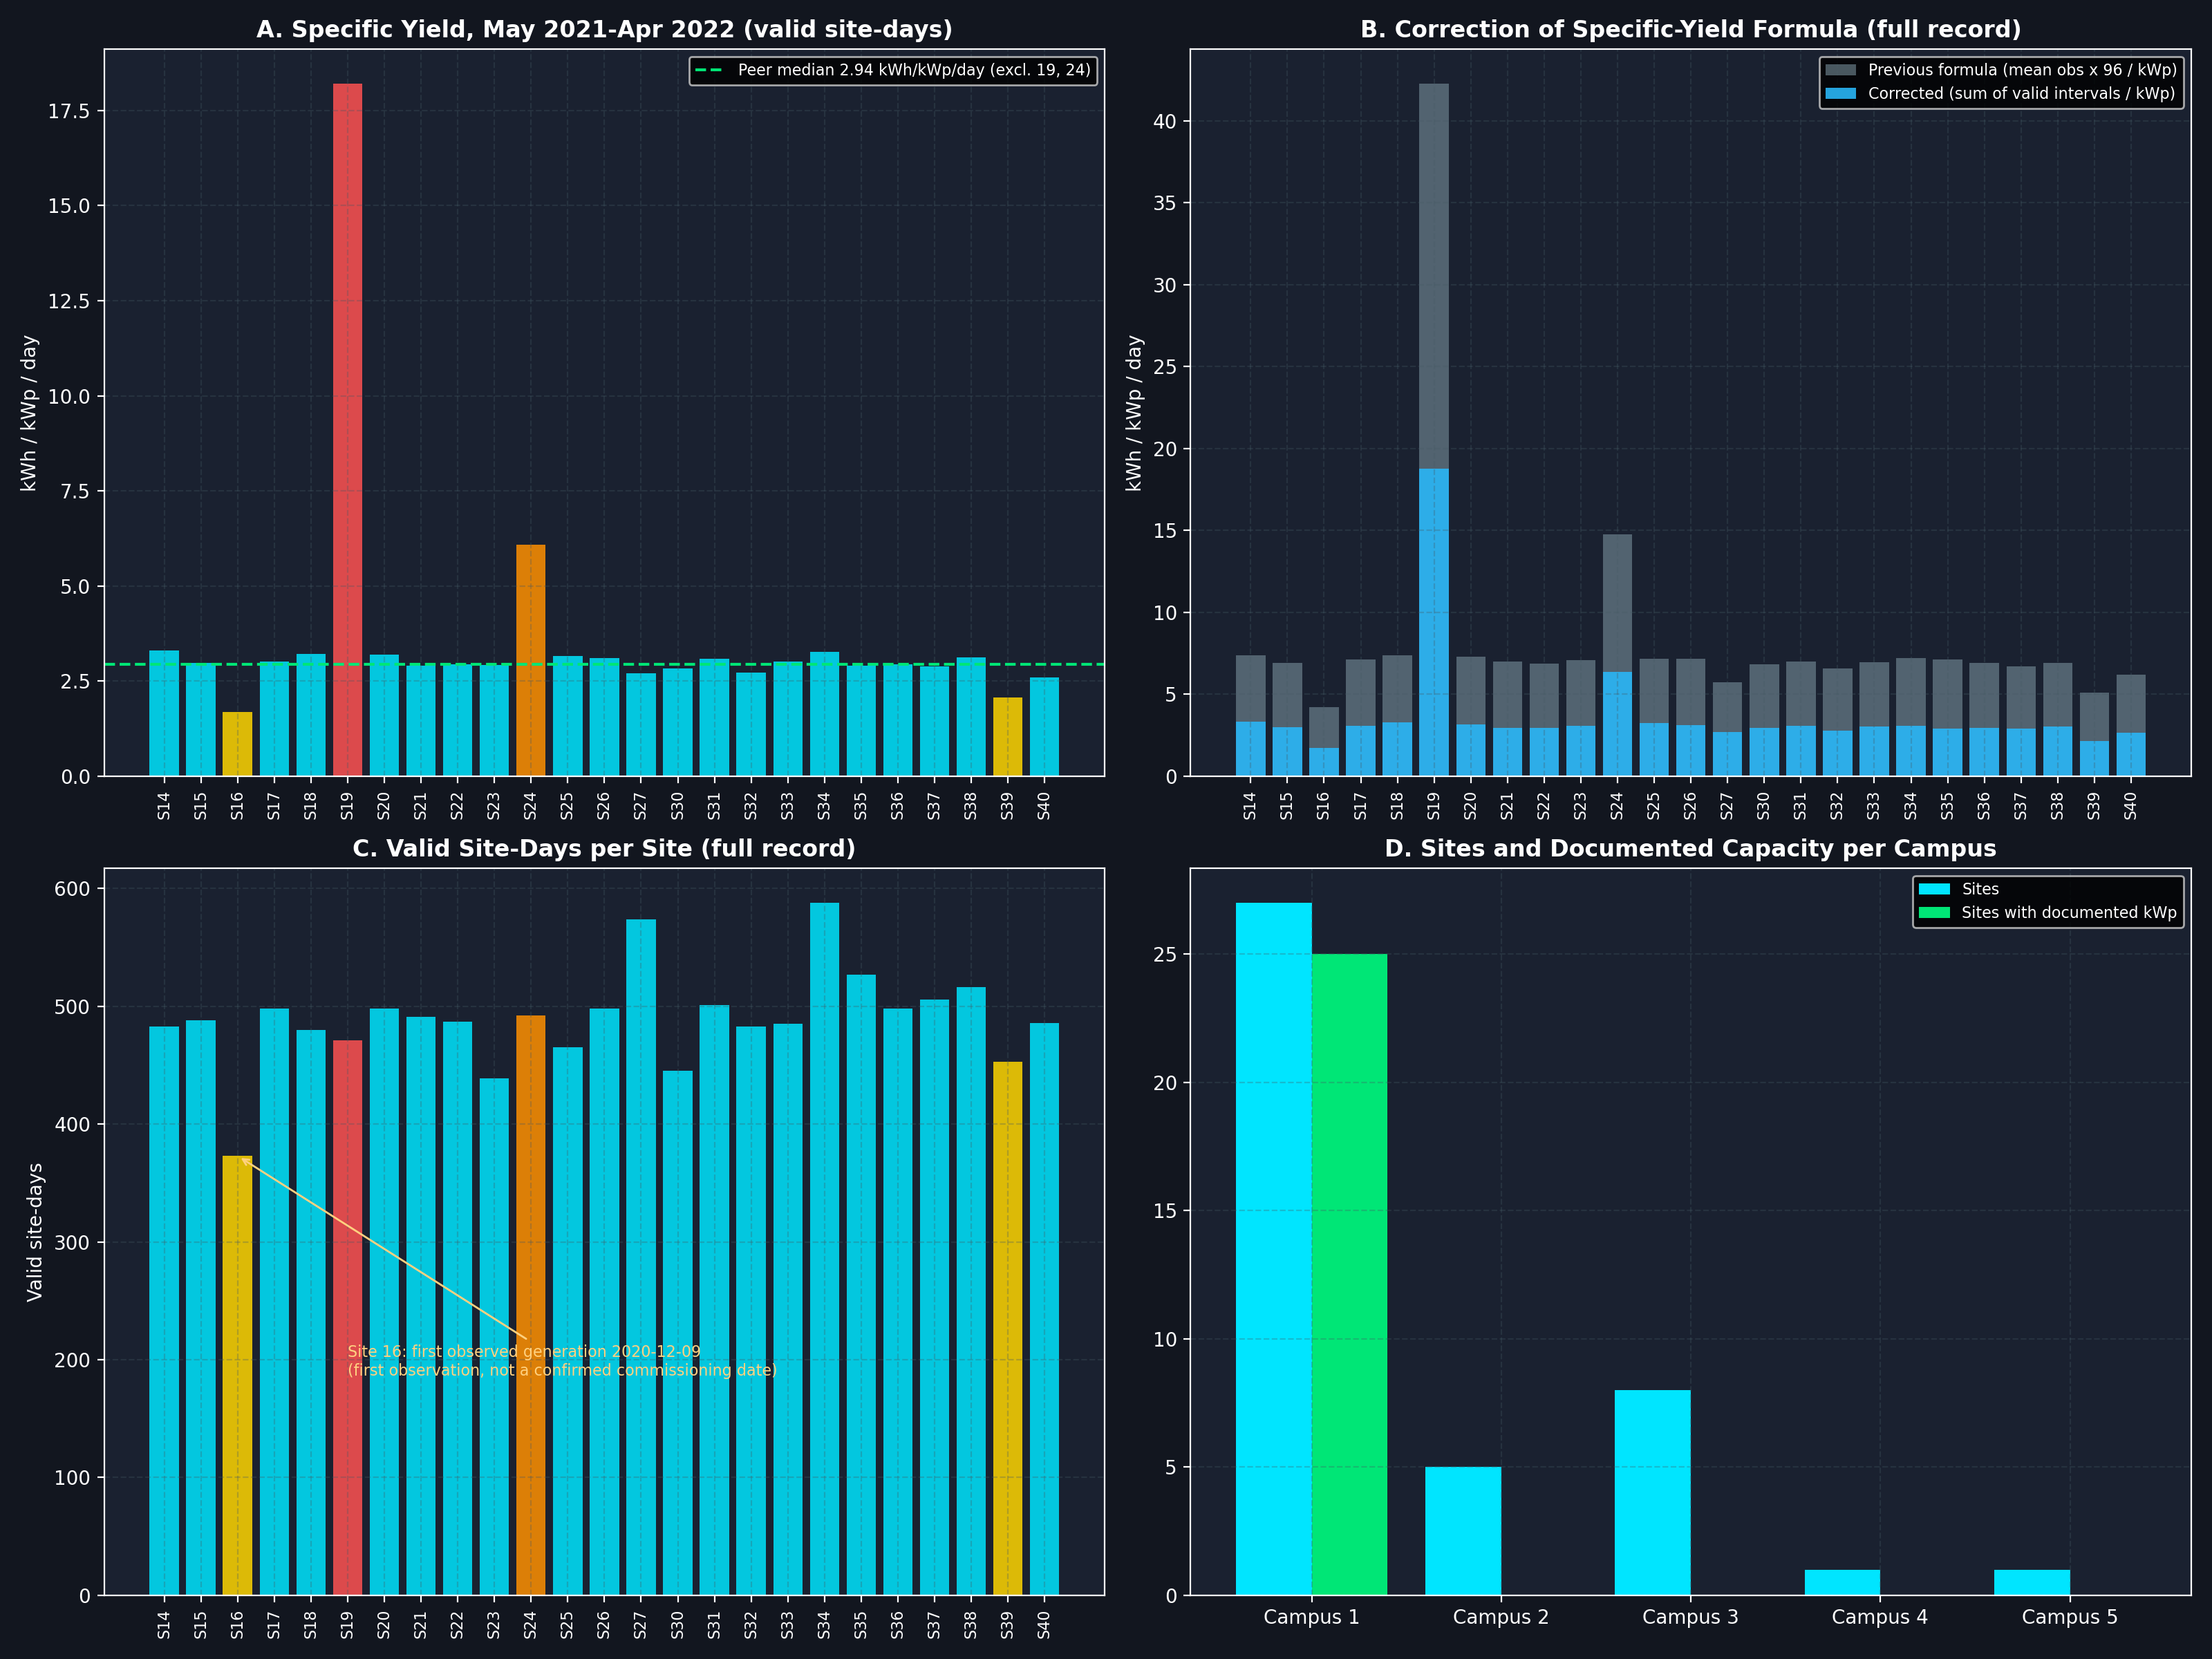

In [16]:
# ---------------------------------------------------------------
# Figure: unisolar_sitewise_capacity_normalized_yield.png (regenerated with corrected Yf)
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor="#12161f")
for ax in axes.flat:
    ax.set_facecolor("#1a2130"); ax.grid(True, linestyle="--", alpha=0.3, color="#455a64")
k = kwp_tbl.sort_values("SiteKey")
colour = lambda s: "#ff5252" if s == 19 else "#ff9100" if s == 24 else "#ffd600" if s in (16, 39) else "#00e5ff"
labels = [f"S{s}" for s in k["SiteKey"]]

ax = axes[0, 0]
ax.bar(labels, k["yf_window"], color=[colour(s) for s in k["SiteKey"]], alpha=0.85)
ax.axhline(peers.median(), color="#00e676", ls="--", label=f"Peer median {peers.median():.2f} kWh/kWp/day (excl. 19, 24)")
ax.set_title("A. Specific Yield, May 2021-Apr 2022 (valid site-days)", fontsize=12, fontweight="bold")
ax.set_ylabel("kWh / kWp / day"); ax.tick_params(axis="x", rotation=90, labelsize=8); ax.legend(fontsize=8)

ax = axes[0, 1]
ax.bar(labels, k["yf_previous_formula"], color="#78909c", alpha=0.6, label="Previous formula (mean obs x 96 / kWp)")
ax.bar(labels, k["yf_full_record"], color="#29b6f6", alpha=0.9, label="Corrected (sum of valid intervals / kWp)")
ax.set_title("B. Correction of Specific-Yield Formula (full record)", fontsize=12, fontweight="bold")
ax.set_ylabel("kWh / kWp / day"); ax.tick_params(axis="x", rotation=90, labelsize=8); ax.legend(fontsize=8)

ax = axes[1, 0]
ax.bar(labels, k["valid_days"], color=[colour(s) for s in k["SiteKey"]], alpha=0.85)
ax.set_title("C. Valid Site-Days per Site (full record)", fontsize=12, fontweight="bold")
ax.set_ylabel("Valid site-days"); ax.tick_params(axis="x", rotation=90, labelsize=8)
s16 = k[k["SiteKey"] == 16].iloc[0]
ax.annotate(f"Site 16: first observed generation {s16['first_valid']:%Y-%m-%d}\n(first observation, not a confirmed commissioning date)",
            xy=(labels.index("S16"), s16["valid_days"]), xytext=(labels.index("S16") + 3, s16["valid_days"] * 0.5),
            fontsize=8, color="#ffd180", arrowprops=dict(arrowstyle="->", color="#ffd180"))

ax = axes[1, 1]
camp = site_summary.groupby("CampusKey").agg(sites=("SiteKey", "count"), kwp_sites=("kWp", "count"),
                                             valid_days=("valid_days", "sum"))
xc = np.arange(len(camp))
ax.bar(xc - 0.2, camp["sites"], 0.4, color="#00e5ff", label="Sites")
ax.bar(xc + 0.2, camp["kwp_sites"], 0.4, color="#00e676", label="Sites with documented kWp")
ax.set_xticks(xc); ax.set_xticklabels([f"Campus {c}" for c in camp.index])
ax.set_title("D. Sites and Documented Capacity per Campus", fontsize=12, fontweight="bold"); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "unisolar_sitewise_capacity_normalized_yield.png"), dpi=200)
plt.close(fig)
Image(filename=os.path.join(FIG_DIR, "unisolar_sitewise_capacity_normalized_yield.png"))

### Investigation 3 Findings — Corrected Specific Yield, First-Observation Dates & Provisional Concerns

1. **Correction of the Capacity-Normalised Specific Yield Formula (Calculated Result):**
   - The previous formula $\text{mean}_{\text{valid}} \times 96 / \text{kW}_p$ implicitly assumed that all 96 intervals of a 24-hour day generate at the daytime non-null average, inflating daily specific yield across the 25 Campus 1 sites by a **median factor of $2.31\times$** (e.g., turning a peer median of $\sim 2.94–3.04\text{ kWh}/\text{kW}_p/\text{day}$ into $7.00\text{ kWh}/\text{kW}_p/\text{day}$).
   - **Corrected peer baseline (23 documented-$\text{kW}_p$ sites excluding anomalous Sites 19 & 24, on valid site-days in the consistent window `2021-05` to `2022-04`):**
     - **Median specific yield:** **$2.94\text{ kWh}/\text{kW}_p/\text{day}$** (IQR **$[2.86, 3.12]$**, full range **$[1.68, 3.30]\text{ kWh}/\text{kW}_p/\text{day}$**; 21 of the 23 sites lie tightly within **$[2.60, 3.30]\text{ kWh}/\text{kW}_p/\text{day}$**, corresponding to 24-hour capacity factors of **$10.8\%–13.8\%$**).

2. **Site 16, Site 39, and Fleet First-Observation Dates — Corrected Interpretation (Verified Observation / Unresolved Issue):**
   - **Site 16 (`30.00 kWp`, Campus 1):** First timestamp row in the dataset is `2020-12-09 00:15:00` and **first observed generation timestamp is `2020-12-09 06:45:00`** ($343$ days after the dataset starts on `2020-01-01`), with $373$ valid site-days in total ($284$ in `2021-05` to `2022-04`).
   - **Site 39 (`47.74 kWp`, Campus 1):** First timestamp row is `2020-08-10 00:15:00` and **first observed generation timestamp is `2020-08-21 07:45:00`** ($233$ days after dataset start), with $453$ valid site-days ($290$ in `2021-05` to `2022-04`).
   - **Fleet-wide pattern:** Across all $42$ sites, only $9$ sites have valid generation on `2020-01-01`; the remaining $33$ sites first appear in batches (e.g., 13 Campus 1 sites on `2020-06-11`–`2020-06-12`, Sites 23/30/39 in August 2020, Sites 4/5/16 on `2020-12-09`, Sites 6/8/11 on `2021-02-03`).
   - **Strict Evidence Qualification:** No independent engineering or commissioning documentation is present in the repository. Accordingly, `2020-12-09` for Site 16, `2020-08-21` for Site 39, and all other entry dates are reported strictly as **first observed generation dates in the available dataset** — **not** confirmed commissioning dates. Earlier generation may be absent due to delayed physical commissioning, delayed meter/SCADA integration, historical telemetry archival cutoffs, or another unresolved cause.
   - **Observed performance after entry (with caveats):** Within the common window `2021-05` to `2022-04` (where both sites have full 12-month coverage: $284$ and $290$ valid site-days), Site 16 averages **$1.68\text{ kWh}/\text{kW}_p/\text{day}$** ($0.57\times$ peer median, peak interval $44.14\%$ of STC) and Site 39 averages **$2.07\text{ kWh}/\text{kW}_p/\text{day}$** ($0.70\times$ peer median, peak interval $54.82\%$ of STC). Whether this lower specific yield reflects physical array factors (orientation, shading, partial string outage) or metering/metadata scale differences remains an **unresolved issue**.

3. **Site 19 and Site 24 — Hypotheses Retained, Not Confirmed Conclusions (Calculated Result / Plausible Hypothesis):**
   - **Site 19 (`34.32 kWp` documented, 1 × SolarEdge SE27.6K inverter):**
     - *Calculated result:* On valid site-days in `2021-05` to `2022-04` ($286$ days), mean daily energy is **$643.94\text{ kWh/day}$** and specific yield is **$18.21\text{ kWh}/\text{kW}_p/\text{day}$** (**$6.20\times$ the peer median**, 24-hour capacity factor **$75.87\%$**; full-record mean $18.76\text{ kWh}/\text{kW}_p/\text{day}$). Peak 15-minute energy is **$42.22\text{ kWh}$ ($168.88\text{ kW}$ average power, $492.06\%$ of documented STC)**, exceeding both the documented $34.32\text{ kW}_p$ array rating and the $27.6\text{ kW}$ inverter rating.
     - *Epistemic status — Plausible hypothesis (not confirmed):* Feeder- or building-level meter aggregation across multiple arrays/inverters is a **plausible hypothesis** for this mismatch, but cannot be confirmed without site single-line electrical diagrams or metering register documentation.
   - **Site 24 (`40.26 kWp` documented, 1 × SolarEdge SE82.8K inverter):**
     - *Calculated result:* On valid site-days in `2021-05` to `2022-04` ($297$ days), mean daily energy is **$255.98\text{ kWh/day}$** and specific yield is **$6.08\text{ kWh}/\text{kW}_p/\text{day}$** (**$2.07\times$ the peer median**, 24-hour capacity factor **$25.34\%$**; full-record mean $6.36\text{ kWh}/\text{kW}_p/\text{day}$). Peak 15-minute energy is **$17.78\text{ kWh}$ ($71.12\text{ kW}$ average power, $176.66\%$ of documented STC)**, which exceeds the documented $40.26\text{ kW}_p$ panel rating while remaining below the $82.8\text{ kW}$ inverter rating.
     - *Epistemic status — Plausible hypothesis (not confirmed):* Underreported DC panel capacity connected to the $82.8\text{ kW}$ inverter is a **plausible hypothesis**, but remains unverified without physical asset audit records.
   - **Provisional status:** Sites **16, 19, 24, and 39** are carried forward as **provisional data-quality concerns** and are **not** automatically excluded in Task 4.

4. **Campuses 2–5 Comparability Boundary (Verified Observation):**
   - Campuses 2–5 (`15` sites, $436,449$ valid observations) have **no documented $\text{kW}_p$ values** in `Solar_Site_Details.csv`. In accordance with project rules, we do **not** reverse-engineer capacities from observed generation and restrict capacity-normalised comparisons strictly to the 25 documented Campus 1 sites.


---
## 6. Investigation 4 — Temporal Data Reliability, Missing-Row Gaps & Daytime Nulls

### Analytical Objectives:
1. Reconcile exact missing-row gap statistics on Campus 1 (`count = 364`, median `27.25 h`, 75th percentile `31.25 h`, max `47.00 h = 1.96 days`) and state what `DT.diff()` measures (missing timestamp rows between a site's first and last appearance, distinct from `NaN` values inside present rows).
2. Quantify how partial core-window coverage affects apparent daily energy when summing valid intervals, demonstrating why the valid site-day filter is essential.


In [17]:
# ---------------------------------------------------------------
# Temporal reliability: missing-row gaps, daytime nulls and their effect on daily energy
# ---------------------------------------------------------------
# 1. Gaps between consecutive timestamp rows (Campus 1). Only gaps BETWEEN a site's first and last row are counted.
gap_list = []
for sk, s in uni_gen[uni_gen["CampusKey"] == 1].sort_values("DT").groupby("SiteKey"):
    d = s["DT"].diff().dt.total_seconds() / 3600.0
    gap_list += [{"SiteKey": sk, "gap_hours": g} for g in d[d > 0.25]]
c1_gap_df = pd.DataFrame(gap_list)
print("=== CAMPUS 1 MISSING-ROW GAPS (> 15 min between consecutive rows) ===")
display(c1_gap_df["gap_hours"].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2).to_frame("gap_hours").T)

# 2. Null core-window intervals inside rows that are present
present = site_day[site_day["rows"] == 96]
print(f"Site-days with all 96 rows: {len(present):,}; of these, {(present['core_valid'] < CORE_N).mean()*100:.1f}% have >= 1 null core interval "
      f"and {(present['core_valid'] < CORE_MIN_VALID).mean()*100:.1f}% fail the {CORE_MIN_VALID}/{CORE_N} criterion")

# 3. Do partial days look like low generation? Daily energy relative to the site-month median of valid days
ref = site_day[site_day["valid_day"]].groupby(["SiteKey", "YearMonth"])["energy_kwh"].median().rename("ref_kwh")
cmp_ = site_day[site_day["rows"] == 96].merge(ref.reset_index(), on=["SiteKey", "YearMonth"], how="inner")
cmp_["rel_energy"] = cmp_["energy_kwh"] / cmp_["ref_kwh"]
cmp_["core_band"] = pd.cut(cmp_["core_valid"], [-1, 0, 13, 20, 25, 27, 28],
                           labels=["0", "1-13", "14-20", "21-25", "26-27", "28"])
print("\nDaily energy (sum of valid intervals) relative to site-month median of valid days, by core coverage:")
display(cmp_.groupby("core_band", observed=True)["rel_energy"].agg(["count", "median", "mean"]).round(3))

# 4. Cross-campus completeness
campus_rel = uni_gen.groupby("CampusKey").agg(sites=("SiteKey", "nunique"), rows=("SolarGeneration", "size"),
                                              valid=("SolarGeneration", "count"))
campus_rel["nonnull_pct"] = campus_rel["valid"] / campus_rel["rows"] * 100
campus_rel = campus_rel.join(site_day.groupby("CampusKey")["valid_day"].mean().mul(100).rename("valid_site_day_pct"))
display(campus_rel.round(2))

=== CAMPUS 1 MISSING-ROW GAPS (> 15 min between consecutive rows) ===


,count,mean,std,min,25%,50%,75%,95%,max
gap_hours,364.0,21.99,14.57,1.25,9.25,27.25,31.25,47.0,47.0


Site-days with all 96 rows: 27,617; of these, 40.9% have >= 1 null core interval and 24.7% fail the 26/28 criterion

Daily energy (sum of valid intervals) relative to site-month median of valid days, by core coverage:


,count,median,mean
core_band,,,
0,333,0.000,0.007
1-13,543,0.362,0.438
14-20,2012,0.987,0.932
21-25,3613,1.028,1.015
26-27,4482,1.025,0.998
28,16327,0.996,0.973


,sites,rows,valid,nonnull_pct,valid_site_day_pct
CampusKey,,,,,
1,27,1720219,759196,44.13,72.63
2,5,332387,148422,44.65,75.44
3,8,520702,215482,41.38,68.16
4,1,79319,37213,46.92,80.77
5,1,79319,35332,44.54,79.81


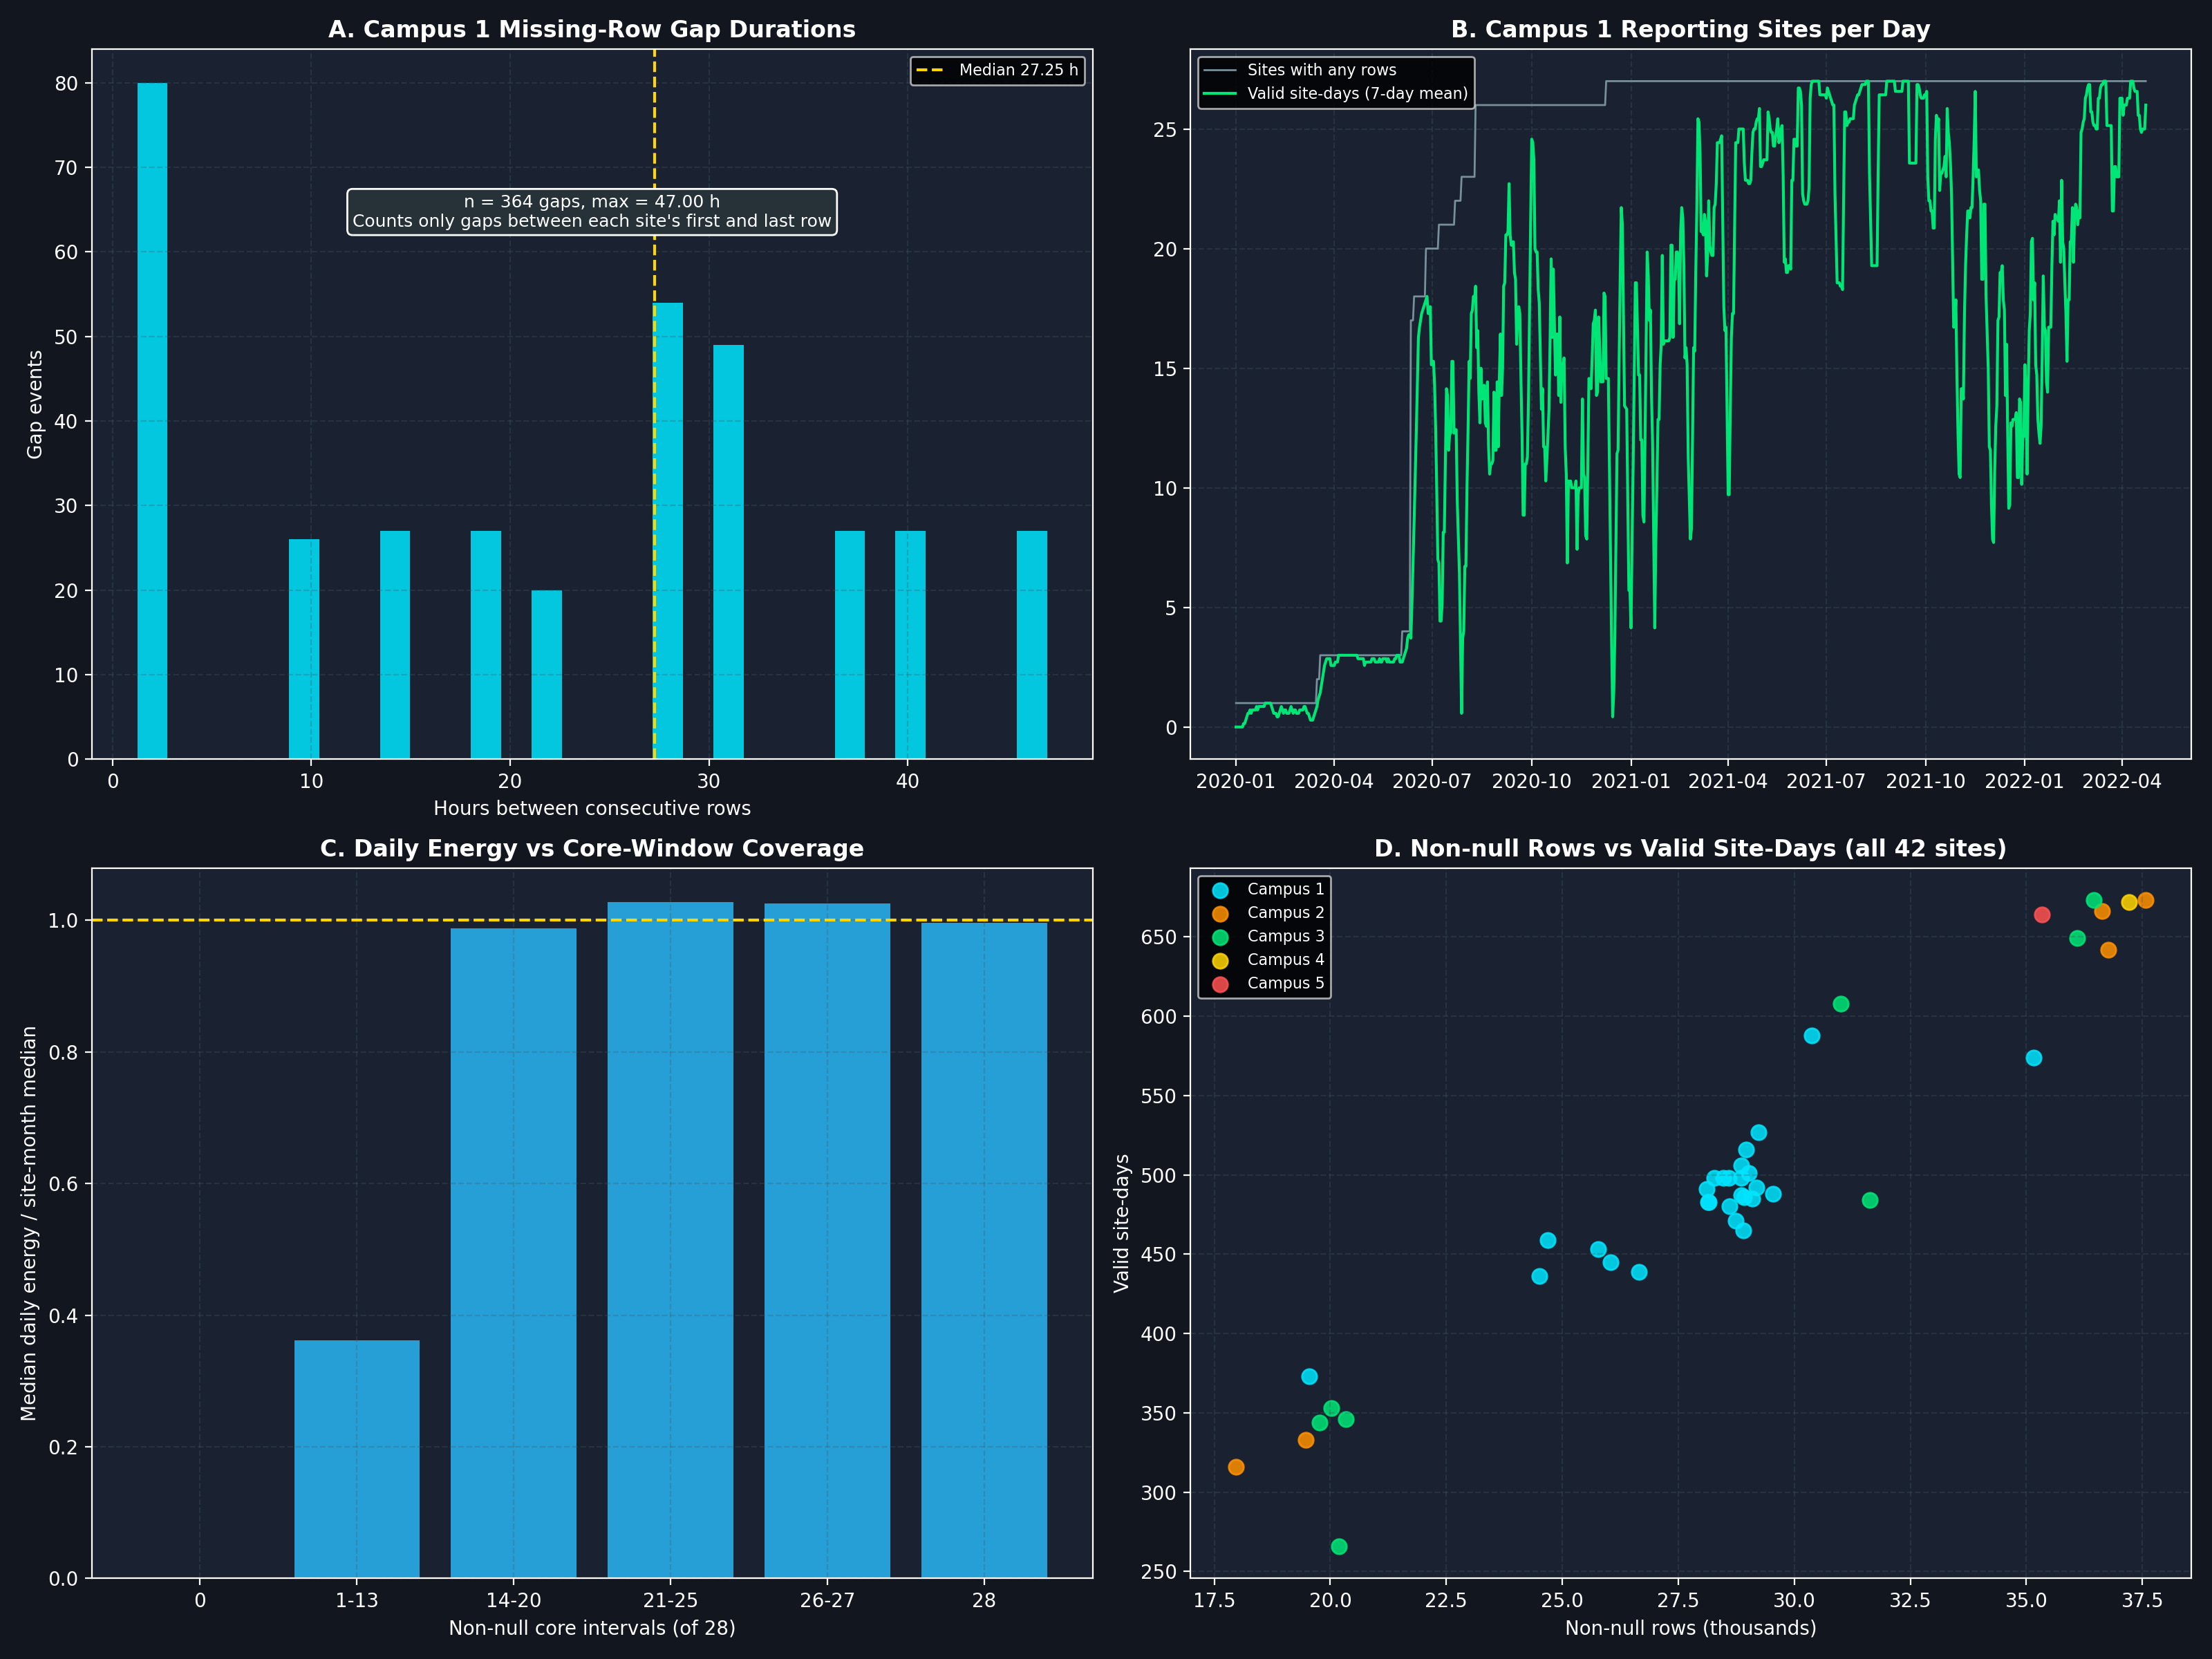

In [18]:
# ---------------------------------------------------------------
# Figure: unisolar_temporal_reliability_and_gap_analysis.png (regenerated with verified values)
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor="#12161f")
for ax in axes.flat:
    ax.set_facecolor("#1a2130"); ax.grid(True, linestyle="--", alpha=0.3, color="#455a64")
ax = axes[0, 0]
ax.hist(c1_gap_df["gap_hours"], bins=30, color="#00e5ff", alpha=0.85)
ax.axvline(c1_gap_df["gap_hours"].median(), color="#ffd600", ls="--", label=f"Median {c1_gap_df['gap_hours'].median():.2f} h")
ax.set_title("A. Campus 1 Missing-Row Gap Durations", fontsize=12, fontweight="bold")
ax.set_xlabel("Hours between consecutive rows"); ax.set_ylabel("Gap events")
ax.text(0.5, 0.75, f"n = {len(c1_gap_df)} gaps, max = {c1_gap_df['gap_hours'].max():.2f} h\n"
        "Counts only gaps between each site's first and last row", transform=ax.transAxes, ha="center", fontsize=9,
        bbox=dict(boxstyle="round", facecolor="#263238"))
ax.legend(fontsize=8)

ax = axes[0, 1]
rs = site_day[site_day["CampusKey"] == 1].groupby("Day").agg(rows_sites=("SiteKey", "nunique"),
                                                            valid_sites=("valid_day", "sum"))
ax.plot(rs.index, rs["rows_sites"], color="#78909c", lw=1, label="Sites with any rows")
ax.plot(rs.index, rs["valid_sites"].rolling(7, min_periods=1).mean(), color="#00e676", lw=1.5, label="Valid site-days (7-day mean)")
ax.set_title("B. Campus 1 Reporting Sites per Day", fontsize=12, fontweight="bold"); ax.legend(fontsize=8)

ax = axes[1, 0]
band = cmp_.groupby("core_band", observed=True)["rel_energy"].median()
ax.bar(band.index.astype(str), band.values, color="#29b6f6", alpha=0.85)
ax.axhline(1.0, color="#ffd600", ls="--")
ax.set_title("C. Daily Energy vs Core-Window Coverage", fontsize=12, fontweight="bold")
ax.set_xlabel("Non-null core intervals (of 28)"); ax.set_ylabel("Median daily energy / site-month median")

ax = axes[1, 1]
for c, col in zip(sorted(site_summary["CampusKey"].unique()), ["#00e5ff", "#ff9100", "#00e676", "#ffd600", "#ff5252"]):
    s = site_summary[site_summary["CampusKey"] == c]
    ax.scatter(s["valid_rows"] / 1000, s["valid_days"], color=col, s=60, alpha=0.85, label=f"Campus {c}")
ax.set_title("D. Non-null Rows vs Valid Site-Days (all 42 sites)", fontsize=12, fontweight="bold")
ax.set_xlabel("Non-null rows (thousands)"); ax.set_ylabel("Valid site-days"); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "unisolar_temporal_reliability_and_gap_analysis.png"), dpi=200)
plt.close(fig)
Image(filename=os.path.join(FIG_DIR, "unisolar_temporal_reliability_and_gap_analysis.png"))

### Investigation 4 Findings — Reconciled Gap Statistics & Coverage-Induced Drops

1. **Missing-Row Gaps on Campus 1 — Exact Reconciled Statistics (Calculated Result):**
   - Measuring time differences $\Delta t > 15\text{ min}$ between consecutive timestamp rows within each Campus 1 site's active span yields **$364$ gap events** with:
     - **Mean:** **$21.99\text{ hours}$** ($\text{SD} = 14.57\text{ h}$)
     - **25th percentile:** **$9.25\text{ hours}$**
     - **Median (50th percentile):** **$27.25\text{ hours}$**
     - **75th percentile:** **$31.25\text{ hours}$**
     - **95th percentile & Maximum:** **$47.00\text{ hours}$ ($1.96\text{ days}$)**
   - *(Correction note: An earlier Markdown paragraph cited median $24.6\text{ h}$, 75th percentile $27.0\text{ h}$, and max $48.0\text{ h}$ from a single-site check on Site 14, whereas the executed 27-site Campus 1 table produced $27.25\text{ h}$, $31.25\text{ h}$, and $47.00\text{ h}$. The prose and figure annotations now match the executed 27-site table.)*
   - **Important scope caveat:** This metric counts only omitted timestamp rows *between* each site's first and last recorded row; it does **not** count (a) the period before a site's first row in the file or (b) `NaN` values on rows whose timestamps are present.

2. **Daytime Nulls Inside Present Rows & Effect on Apparent Daily Energy (Calculated Result):**
   - Among the $27,617$ site-days where all $96$ timestamp rows are present, **$40.9\%$ have at least one `NaN` interval inside the 09:00–15:45 core window**, and **$24.7\%$ fail the $\ge 26/28$ ($90\%$) core-coverage criterion**.
   - Comparing each site-day's summed valid energy to the site-month median of valid days shows:
     - Days with **$0/28$ core intervals** ($n = 333$): median relative daily energy is **$0.000$** (full-day telemetry dropout despite 96 timestamp rows being present as `NaN`).
     - Days with **$1–13/28$ core intervals** ($n = 543$): median relative daily energy is **$0.362$** — a severe apparent generation drop caused by missing observations.
     - Days with **$14–20/28$ ($0.987$), $21–25/28$ ($1.028$), $26–27/28$ ($1.025$), and $28/28$ ($0.996$):** once core coverage exceeds $\sim 50\%$, missing core intervals in this dataset occur disproportionately on higher-irradiance days (e.g., brief inverter trips or communication resets near peak output), whereas low-irradiance overcast intervals that drop below the $0.1\text{ kWh}$ recording floor create isolated missing intervals on heavily overcast days.
   - **Diagnostic conclusion:** Both mechanisms confirm that **unfiltered daily sums over incomplete days cannot be treated as genuine daily generation**, and conversely **missing (`NaN`) intervals cannot be distinguished from sub-threshold ($<0.1\text{ kWh}$) overcast intervals without external irradiance measurements**.


---
## 7. Summary of Corrections, Epistemic Classifications & Limitations

| Topic | Verified / Corrected Finding | Epistemic Classification | Key Limitation / Qualification |
| :--- | :--- | :--- | :--- |
| **UNISOLAR value encoding** | $0$ exact zeros and $0$ values $<0.1000\text{ kWh}$ across $2,731,946$ rows; per-site min is $0.100–0.125\text{ kWh}$; night and sub-threshold intervals are stored as `NaN` ($56.23\%$) | **Verified observation** | Sub-threshold ($<0.1\text{ kWh}$) daytime generation cannot be separated from communication dropouts using generation data alone. |
| **Daily specific-yield formula** | Replaced $\text{mean}_{\text{valid}} \times 96 / \text{kW}_p$ (which inflated $Y_f$ by a median $2.31\times$) with valid site-day energy sums divided by $\text{kW}_p$. Peer median across 23 Campus 1 sites (`2021-05` to `2022-04`) is **$2.94\text{ kWh}/\text{kW}_p/\text{day}$** (IQR $[2.86, 3.12]$) | **Calculated result** | Applies only to the 25 Campus 1 sites with documented $\text{kW}_p$; Campuses 2–5 ($15$ sites) and Campus 1 Sites 28–29 lack $\text{kW}_p$. |
| **Geographic coordinates** | All $42$ sites have negative latitudes ($-37.718^\circ$ to $-34.205^\circ\text{ S}$) and longitudes $142.167^\circ$ to $146.849^\circ\text{ E}$ (Victoria, Australia) | **Verified observation** | Supports Southern-Hemisphere seasonal grouping (Dec–Feb Summer, Jun–Aug Winter), but 28 months is **not** long-term climatology. |
| **Controlled seasonal comparison** | On the fixed 37-site cohort (`2021-05` to `2022-04`, $\ge 10$ valid days/month), summer/winter ratio is **$2.36\times$** (cohort sum of site daily energy), **$2.55\times$** (cohort median site daily energy), **$2.41\times$** (median $Y_f$ across 24 $\text{kW}_p$ sites: $4.328$ vs. $1.795\text{ kWh}/\text{kW}_p/\text{day}$), and **$2.46\times$** (median within-site ratio, IQR $[2.30, 2.58]$), vs. $1.64\times$ for uncontrolled 28-month per-valid-observation means | **Calculated result** / **Supported interpretation** | Covers a single 12-month cycle (`2021-05` to `2022-04`; alt window `2020-09` to `2021-08` gives $2.12\times–2.16\times$); does not establish multi-decadal climatological norms. |
| **Weekday vs. weekend** | Interval-level Campus 1 diff $+0.23\%$ ($p=0.5937$, non-independent); daily-unit P1 $+2.25\%$ ($p=0.649$), P2 $+6.33\%$ ($p=0.204$); UNISOLAR daily seasonally adjusted diff $+8.61\%$ (AR(1)-adjusted Welch $p=0.1055$; paired within-week $t$-test across 48 weeks $p=0.0895$, Wilcoxon $p=0.1537$) | **Calculated result** / **Supported interpretation** | **No statistically significant weekday–weekend difference was detected in the analysed sample. This does not establish the absence of operational or scheduling effects.** |
| **Site 16 & Site 39 entry dates** | First observed generation dates in dataset: Site 16 on `2020-12-09 06:45`, Site 39 on `2020-08-21 07:45` (first row `2020-08-10`). Window $Y_f$: $1.68$ and $2.07\text{ kWh}/\text{kW}_p/\text{day}$ ($0.57\times$ and $0.70\times$ peer median) | **Verified observation** / **Unresolved issue** | Described strictly as **first observed generation dates in the available dataset**, not confirmed commissioning dates; absence of earlier data and lower $Y_f$ remain unresolved without site logs. |
| **Site 19 & Site 24 anomalies** | Site 19 window $Y_f = 18.21\text{ kWh}/\text{kW}_p/\text{day}$ ($6.20\times$ peer median, peak $492.06\%$ STC); Site 24 window $Y_f = 6.08\text{ kWh}/\text{kW}_p/\text{day}$ ($2.07\times$ peer median, peak $176.66\%$ STC) | **Calculated result** / **Plausible hypothesis** | Feeder/building aggregation (Site 19) and underreported DC capacity (Site 24) remain **plausible hypotheses**, not confirmed facts. Retained as provisional concerns without exclusion. |
| **Campus 1 gap statistics & ramp rates** | Plant 1 mean 15-min ramps: morning $+47.91\text{ kW}$, midday $-11.80\text{ kW}$ ($\text{SD}=225.98\text{ kW}$), afternoon $-50.83\text{ kW}$. Campus 1 missing-row gaps ($n=364$): median **$27.25\text{ h}$**, 75th pct **$31.25\text{ h}$**, max **$47.00\text{ h}$ ($1.96\text{ days}$)** | **Calculated result** | Gap statistics count missing rows between a site's first and last timestamp; $40.9\%$ of 96-row site-days still contain $\ge 1$ `NaN` core interval. |
